In [21]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [54]:
import sys
import os

sys.path.append("../..")

import json
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import dask
from dask.diagnostics import ProgressBar
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

from cordex2energy.data_processing.load_data import ClimateModelData
from cordex2energy.utils.constants import EXTENT_CH, CH_TURBINES, EUROPE_TURBINES, REFERENCE_PERIOD, NEAR_FUTURE_PERIOD, MID_CENTURY_PERIOD
from cordex2energy.utils.utils_xarray import sel_extent

sns.set_style("whitegrid", {"grid.color": ".93"})
sns.set_palette("colorblind")

In [23]:
paths = json.load(open("../../paths_so4.json"))
path_data_processed = Path(paths["path_data_processed"])
path_data_temporary = Path(paths["path_data_temporary"])

In [24]:
dask.config.set(num_workers=10)
dask.config.set({"array.chunk-size": "500MiB"})


os.environ["OMP_NUM_THREADS"] = "1"  # OpenMP
os.environ["MKL_NUM_THREADS"] = "1"  # MKL
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # OpenBLAS
os.environ["NUMEXPR_NUM_THREADS"] = "1"  # numexpr

dask.config.set({"logging.distributed": "error"})
dask.config.set(num_workers=16, threads_per_worker=16)
dask.config.set({"array.chunk-size": "400MiB"})

dask.config.set({'distributed.worker.memory.target': 0.75})  # Spill to disk at 75% usage
dask.config.set({'distributed.worker.memory.spill': 0.8})   # Start spilling at 80%
dask.config.set({'distributed.worker.memory.pause': 0.9})   # Pause worker at 90%

In [25]:
climate_scenario = "rcp85"

In [26]:
path_energy_europe = path_data_processed / "energy" / "europe"
path_energy_ch = path_data_processed / "energy" / "ch"

In [31]:
selected_turbine_europe = EUROPE_TURBINES[0]
selected_turbine_ch = CH_TURBINES[0]

In [20]:
home_lat = 47.4
home_lon = 8.59

# Load data

In [8]:
# Load PV
path_pv = path_energy_europe / "pv"
path_pv_zarr = sorted(path_pv.glob(f"*/*{climate_scenario}*.zarr"))
data_var_pv = list(xr.open_zarr(path_pv_zarr[0], chunks="auto").data_vars.keys())[0]
ds_pv = sel_extent(
    xr.concat(
        [xr.open_zarr(path, chunks="auto") for path in path_pv_zarr], dim="model"
    ).rename({data_var_pv: "pv"}),
    extent=EXTENT_CH,
)
ds_pv["model"] = [path.stem.split("pv_")[1] for path in path_pv_zarr]

In [32]:
path_wind_ch = path_energy_ch / "wind_power"
path_wind_ch_zarr = sorted(path_wind_ch.glob(f"*{climate_scenario}*.zarr"))

ds_wind_ch = xr.concat(
    [
        xr.open_zarr(path, chunks="auto")[[selected_turbine_ch.replace("/", "_")]]
        for path in path_wind_ch_zarr
    ],
    dim="model",
)
ds_wind_ch["model"] = [path.stem.split("wind_power_")[1] for path in path_wind_ch_zarr]
data_var_wind_ch = list(ds_wind_ch.data_vars.keys())[0]
ds_wind_ch = ds_wind_ch.rename({data_var_wind_ch: "wind"})

In [33]:
zurich_pv = ds_pv.sel(lat=home_lat, lon=home_lon, method="nearest")
zurich_wind = ds_wind_ch.sel(lat=home_lat, lon=home_lon, method="nearest")

# Analysis

In [81]:
timeseries_pv = {}
timeseries_wind = {}

year = 2035
months = [6]
for model in zurich_pv.model.values:
    with ProgressBar():
        timeseries_pv[model] = zurich_pv.sel(
            model=model, time=(zurich_pv.time.dt.year == year) & (zurich_pv.time.dt.month.isin(months))
        ).pv.compute()
        timeseries_wind[model] = zurich_wind.sel(
            model=model, time=(zurich_wind.time.dt.year == year) & (zurich_wind.time.dt.month.isin(months))
        ).wind.compute()

[                                        ] | 0% Completed | 266.64 us

[########################################] | 100% Completed | 6.75 ss
[########################################] | 100% Completed | 406.60 ms
[########################################] | 100% Completed | 3.93 sms
[########################################] | 100% Completed | 423.54 ms
[########################################] | 100% Completed | 30.61 s
[########################################] | 100% Completed | 202.07 ms
[########################################] | 100% Completed | 302.81 ms
[########################################] | 100% Completed | 907.88 ms
[########################################] | 100% Completed | 403.58 ms
[########################################] | 100% Completed | 202.67 ms
[########################################] | 100% Completed | 303.20 ms
[########################################] | 100% Completed | 202.35 ms
[########################################] | 100% Completed | 404.65 ms
[########################################] | 100% Completed | 202.39 

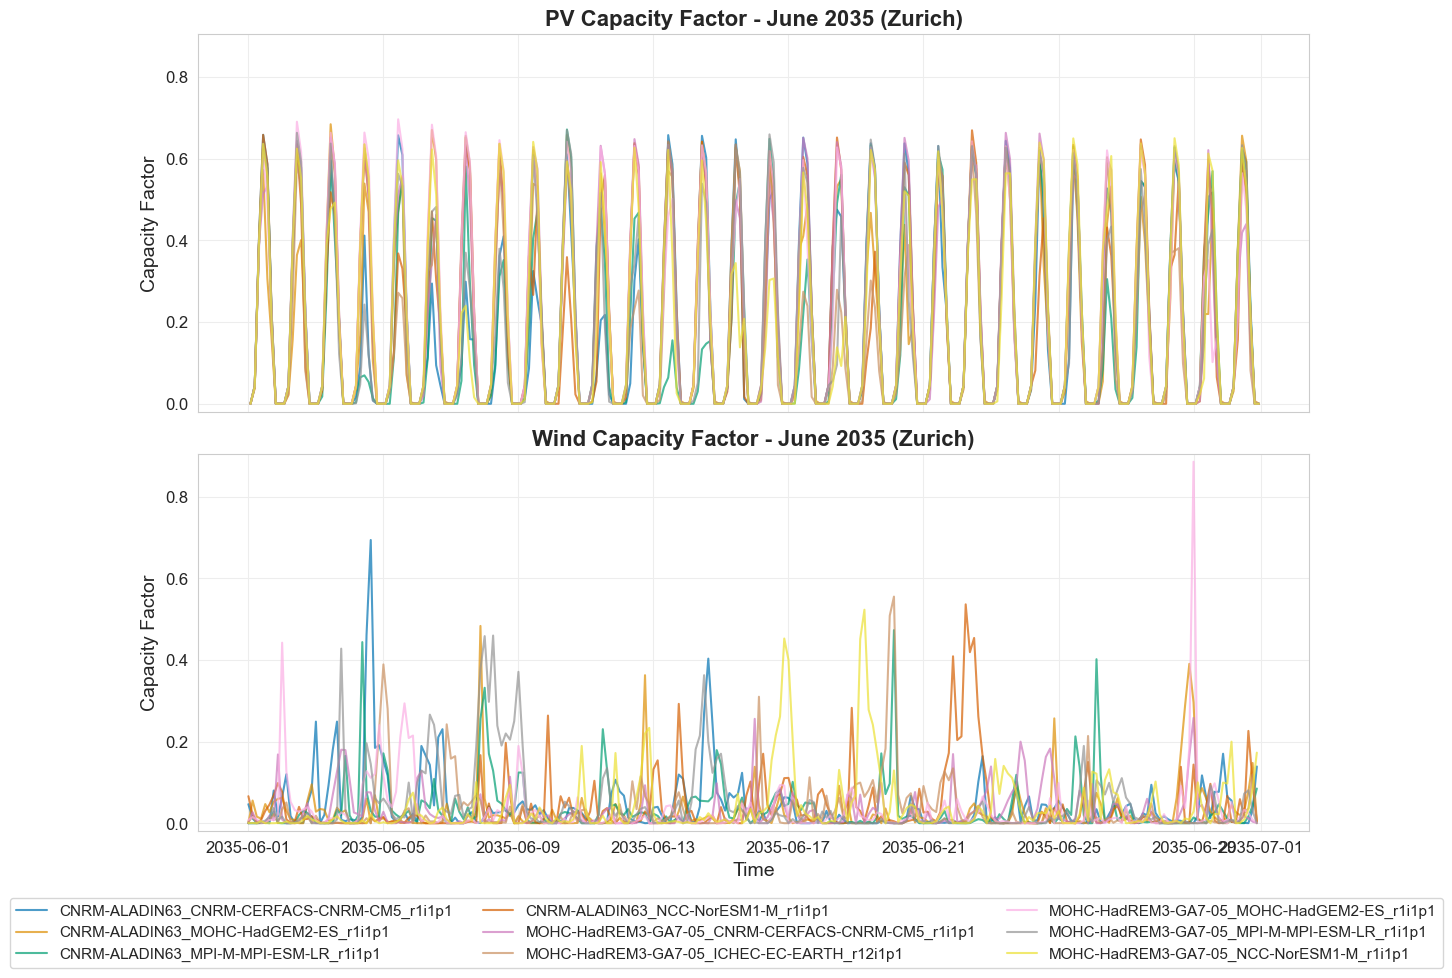

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

# Calculate common y-axis limits
pv_min = min([data.min().values for data in timeseries_pv.values()])
pv_max = max([data.max().values for data in timeseries_pv.values()])
wind_min = min([data.min().values for data in timeseries_wind.values()])
wind_max = max([data.max().values for data in timeseries_wind.values()])
y_min = min(pv_min, wind_min) - 0.02
y_max = max(pv_max, wind_max) + 0.02

# PV timeseries
ax = axes[0]
for model, data in timeseries_pv.items():
    ax.plot(data.time, data, label=model.split(f"_{climate_scenario}")[0], alpha=0.7, linewidth=1.5)
ax.set_ylabel("Capacity Factor", fontsize=14)
ax.set_title("PV Capacity Factor - June 2035 (Zurich)", fontsize=16, fontweight='bold')
ax.set_ylim(y_min, y_max)

# Wind timeseries
ax = axes[1]
for model, data in timeseries_wind.items():
    ax.plot(data.time, data, label=model.split(f"_{climate_scenario}")[0], alpha=0.7, linewidth=1.5)
ax.set_xlabel("Time", fontsize=14)
ax.set_ylabel("Capacity Factor", fontsize=14)
ax.set_title("Wind Capacity Factor - June 2035 (Zurich)", fontsize=16, fontweight='bold')
ax.set_ylim(y_min, y_max)

# Common legend below second subplot
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.09),
           ncol=3, fontsize=11, frameon=True)

for ax in axes:
    ax.tick_params(axis='both', which='major', labelsize=12)

plt.tight_layout()
plt.savefig("figs/zurich_pv_wind_june2035.png", bbox_inches='tight', dpi=300)
plt.show()

In [61]:
# Extract June data for each time period and compute 3-hourly averages
periods = {
    'Reference': REFERENCE_PERIOD,
    'Near Future': NEAR_FUTURE_PERIOD,
    'Mid Century': MID_CENTURY_PERIOD
}

# Prepare 3-hourly averaged data for June
june_3h_pv = {}
june_3h_wind = {}

for period_name, years in periods.items():
    # Filter for June in the specified years
    june_pv = zurich_pv.sel(time=slice(*years))
    june_pv = june_pv.sel(time=(june_pv.time.dt.month == 6))
    june_wind = zurich_wind.sel(time=slice(*years))
    june_wind = june_wind.sel(time=(june_wind.time.dt.month == 6))

    # Resample to 3-hourly and take mean
    june_3h_pv[period_name] = june_pv.pv.resample(time='3h').mean()
    june_3h_wind[period_name] = june_wind.wind.resample(time='3h').mean()

# Compute average 3-hourly pattern (by hour of day)
period_3h_pattern_pv = {}
period_3h_pattern_wind = {}

for period_name in periods.keys():
    with ProgressBar():
        # Group by 3-hour bins (0, 3, 6, 9, 12, 15, 18, 21)
        pv_3h = june_3h_pv[period_name].groupby(june_3h_pv[period_name].time.dt.hour).mean(dim='time').compute()
        wind_3h = june_3h_wind[period_name].groupby(june_3h_wind[period_name].time.dt.hour).mean(dim='time').compute()

    period_3h_pattern_pv[period_name] = pv_3h
    period_3h_pattern_wind[period_name] = wind_3h

/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/xarray/core/groupby.py:668: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  index_grouper = pd.Grouper(
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/xarray/core/groupby.py:668: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  index_grouper = pd.Grouper(
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/xarray/core/groupby.py:668: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  index_grouper = pd.Grouper(
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/xarray/core/groupby.py:668: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  index_grouper = pd.Grouper(
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packa

[########################################] | 100% Completed | 8.26 ss
[########################################] | 100% Completed | 8.92 sms
[########################################] | 100% Completed | 6.92 sms
[########################################] | 100% Completed | 6.13 sms
[########################################] | 100% Completed | 4.43 sms
[########################################] | 100% Completed | 4.97 ss


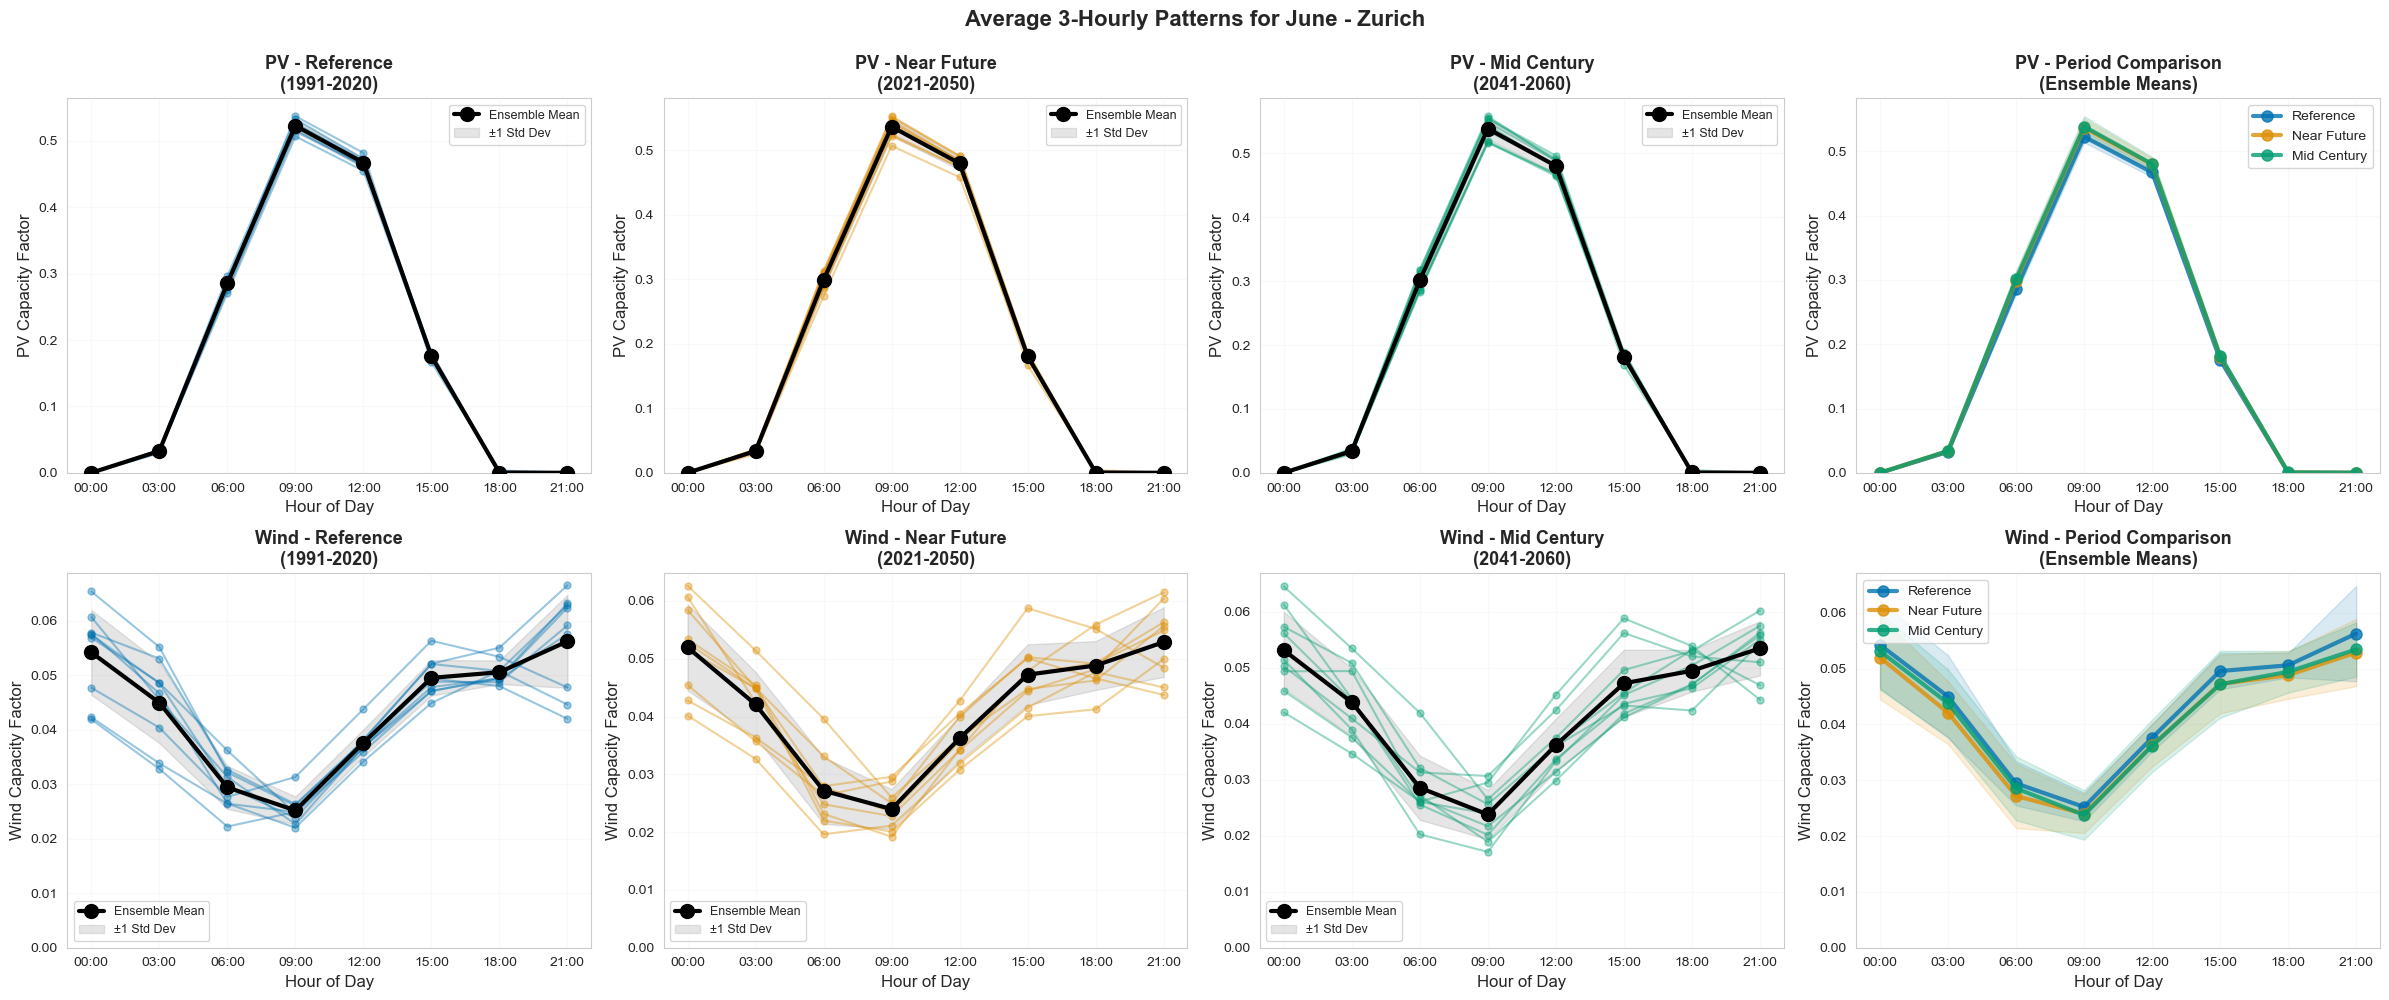

In [63]:
# Create visualization
fig, axes = plt.subplots(2, 4, figsize=(24, 10))

colors_periods = {'Reference': sns.color_palette("colorblind")[0], 'Near Future': sns.color_palette("colorblind")[1], 'Mid Century': sns.color_palette("colorblind")[2]}
hour_labels = ['00:00', '03:00', '06:00', '09:00', '12:00', '15:00', '18:00', '21:00']

# PV 3-hourly patterns by period
for idx, (period_name, pv_pattern) in enumerate(period_3h_pattern_pv.items()):
    ax = axes[0, idx]

    # Plot individual models
    for model in pv_pattern.model.values:
        model_data = pv_pattern.sel(model=model)
        ax.plot(model_data.hour, model_data,
                'o-', alpha=0.4, linewidth=1.5, markersize=5,
                color=colors_periods[period_name])

    # Plot ensemble mean
    ensemble_mean = pv_pattern.mean(dim='model')
    ensemble_std = pv_pattern.std(dim='model')
    ax.plot(pv_pattern.hour, ensemble_mean,
            'o-', linewidth=3, markersize=10, label='Ensemble Mean',
            color='black', zorder=10)
    ax.fill_between(pv_pattern.hour,
                    ensemble_mean - ensemble_std,
                    ensemble_mean + ensemble_std,
                    alpha=0.2, color='gray', label='±1 Std Dev')

    ax.set_xlabel('Hour of Day', fontsize=12)
    ax.set_ylabel('PV Capacity Factor', fontsize=12)
    ax.set_title(f'PV - {period_name}\n({periods[period_name][0]}-{periods[period_name][-1]})',
                 fontsize=13, fontweight='bold')
    ax.set_xticks(range(0, 24, 3))
    ax.set_xticklabels(hour_labels)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(bottom=0)

# PV comparison plot - all periods overlaid
ax = axes[0, 3]
for period_name, pv_pattern in period_3h_pattern_pv.items():
    ensemble_mean = pv_pattern.mean(dim='model')
    ensemble_std = pv_pattern.std(dim='model')

    ax.plot(pv_pattern.hour, ensemble_mean,
            'o-', linewidth=3, markersize=8, label=period_name,
            color=colors_periods[period_name], alpha=0.8)
    ax.fill_between(pv_pattern.hour,
                    ensemble_mean - ensemble_std,
                    ensemble_mean + ensemble_std,
                    alpha=0.15, color=colors_periods[period_name])

ax.set_xlabel('Hour of Day', fontsize=12)
ax.set_ylabel('PV Capacity Factor', fontsize=12)
ax.set_title('PV - Period Comparison\n(Ensemble Means)',
             fontsize=13, fontweight='bold')
ax.set_xticks(range(0, 24, 3))
ax.set_xticklabels(hour_labels)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)

# Wind 3-hourly patterns by period
for idx, (period_name, wind_pattern) in enumerate(period_3h_pattern_wind.items()):
    ax = axes[1, idx]

    # Plot individual models
    for model in wind_pattern.model.values:
        model_data = wind_pattern.sel(model=model)
        ax.plot(model_data.hour, model_data,
                'o-', alpha=0.4, linewidth=1.5, markersize=5,
                color=colors_periods[period_name])

    # Plot ensemble mean
    ensemble_mean = wind_pattern.mean(dim='model')
    ensemble_std = wind_pattern.std(dim='model')
    ax.plot(wind_pattern.hour, ensemble_mean,
            'o-', linewidth=3, markersize=10, label='Ensemble Mean',
            color='black', zorder=10)
    ax.fill_between(wind_pattern.hour,
                    ensemble_mean - ensemble_std,
                    ensemble_mean + ensemble_std,
                    alpha=0.2, color='gray', label='±1 Std Dev')

    ax.set_xlabel('Hour of Day', fontsize=12)
    ax.set_ylabel('Wind Capacity Factor', fontsize=12)
    ax.set_title(f'Wind - {period_name}\n({periods[period_name][0]}-{periods[period_name][-1]})',
                 fontsize=13, fontweight='bold')
    ax.set_xticks(range(0, 24, 3))
    ax.set_xticklabels(hour_labels)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(bottom=0)

# Wind comparison plot - all periods overlaid
ax = axes[1, 3]
for period_name, wind_pattern in period_3h_pattern_wind.items():
    ensemble_mean = wind_pattern.mean(dim='model')
    ensemble_std = wind_pattern.std(dim='model')

    ax.plot(wind_pattern.hour, ensemble_mean,
            'o-', linewidth=3, markersize=8, label=period_name,
            color=colors_periods[period_name], alpha=0.8)
    ax.fill_between(wind_pattern.hour,
                    ensemble_mean - ensemble_std,
                    ensemble_mean + ensemble_std,
                    alpha=0.15, color=colors_periods[period_name])

ax.set_xlabel('Hour of Day', fontsize=12)
ax.set_ylabel('Wind Capacity Factor', fontsize=12)
ax.set_title('Wind - Period Comparison\n(Ensemble Means)',
             fontsize=13, fontweight='bold')
ax.set_xticks(range(0, 24, 3))
ax.set_xticklabels(hour_labels)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)

plt.suptitle('Average 3-Hourly Patterns for June - Zurich',
             fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

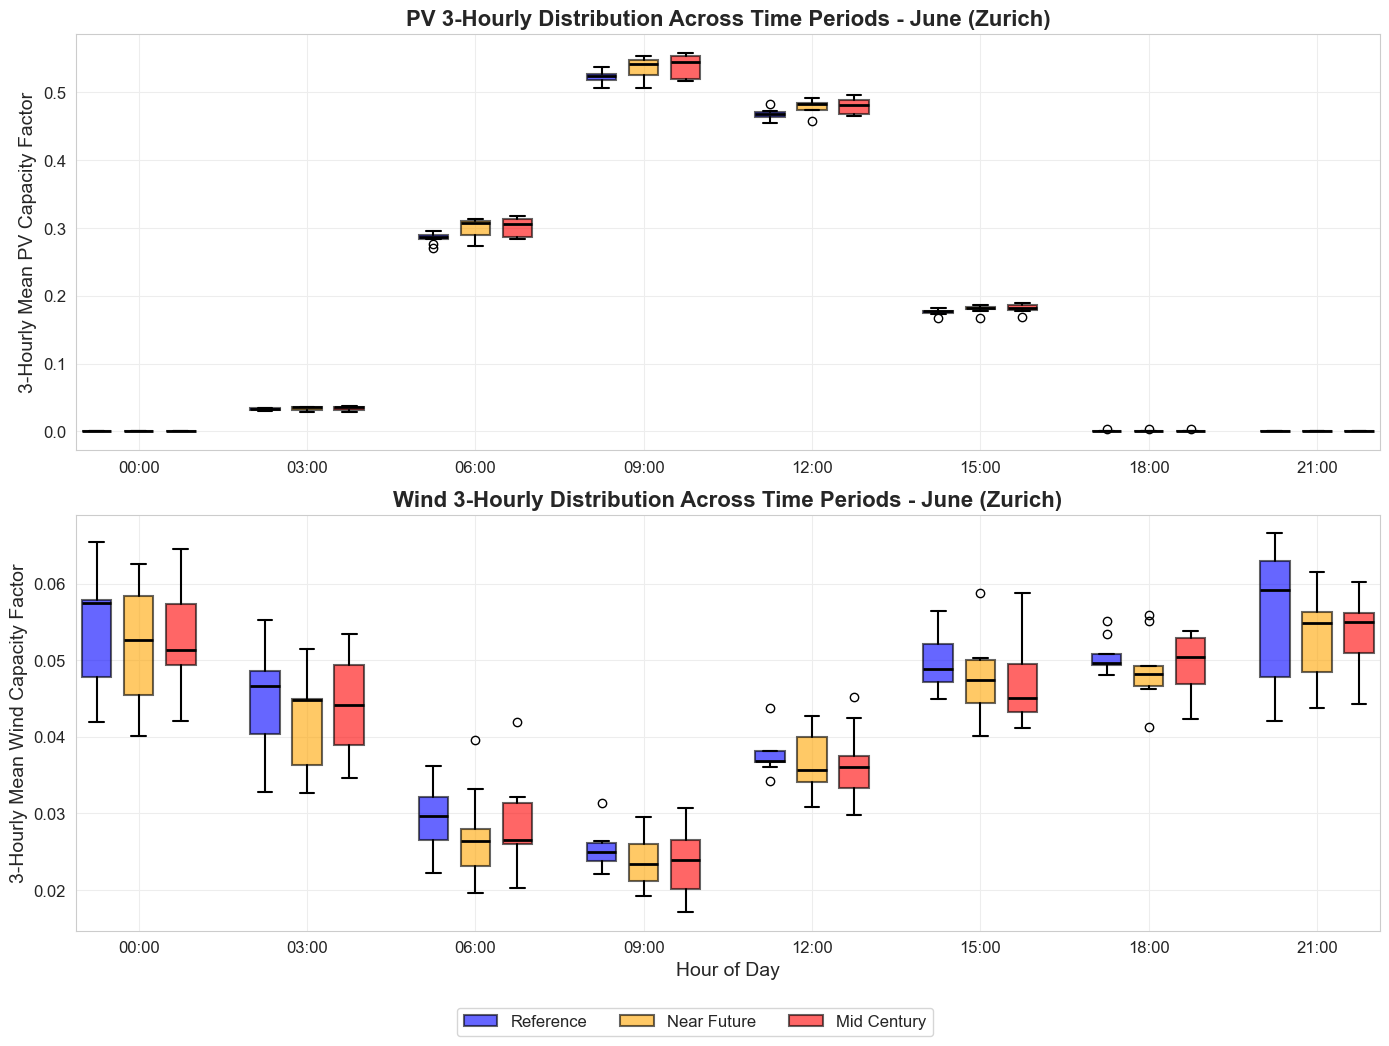

In [101]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

hour_labels_short = ['00:00', '03:00', '06:00', '09:00', '12:00', '15:00', '18:00', '21:00']
colors_periods = {'Reference': 'blue', 'Near Future': 'orange', 'Mid Century': 'red'}

# PV 3-hourly boxplots
ax = axes[0]
positions = []
box_data_pv = []

# Get the available hours from the data
available_hours = sorted([h for h in period_3h_pattern_pv['Reference'].hour.values])

for hour_idx, hour in enumerate(available_hours):
    for period_idx, (period_name, hourly_pv) in enumerate(period_3h_pattern_pv.items()):
        # Get all model values for this hour
        hour_values = hourly_pv.sel(hour=hour).values
        box_data_pv.append(hour_values)

        # Calculate position: hour groups with spacing, periods side-by-side
        pos = hour_idx * 4 + period_idx
        positions.append(pos)

bp = ax.boxplot(box_data_pv, positions=positions, widths=0.7,
                patch_artist=True, showfliers=True,
                boxprops=dict(linewidth=1.5),
                medianprops=dict(color='black', linewidth=2),
                whiskerprops=dict(linewidth=1.5),
                capprops=dict(linewidth=1.5))

# Color the boxes by period
for patch_idx, patch in enumerate(bp['boxes']):
    period_idx = patch_idx % 3
    period_name = list(period_3h_pattern_pv.keys())[period_idx]
    patch.set_facecolor(colors_periods[period_name])
    patch.set_alpha(0.6)

ax.set_ylabel('3-Hourly Mean PV Capacity Factor', fontsize=14)
ax.set_title('PV 3-Hourly Distribution Across Time Periods - June (Zurich)', fontsize=16, fontweight='bold')
ax.set_xticks([i * 4 + 1 for i in range(len(available_hours))])
ax.set_xticklabels([hour_labels_short[available_hours.index(h)] for h in available_hours], fontsize=12)
ax.tick_params(axis='y', labelsize=12)

# Wind 3-hourly boxplots
ax = axes[1]
positions = []
box_data_wind = []

for hour_idx, hour in enumerate(available_hours):
    for period_idx, (period_name, hourly_wind) in enumerate(period_3h_pattern_wind.items()):
        # Get all model values for this hour
        hour_values = hourly_wind.sel(hour=hour).values
        box_data_wind.append(hour_values)

        # Calculate position: hour groups with spacing, periods side-by-side
        pos = hour_idx * 4 + period_idx
        positions.append(pos)

bp = ax.boxplot(box_data_wind, positions=positions, widths=0.7,
                patch_artist=True, showfliers=True,
                boxprops=dict(linewidth=1.5),
                medianprops=dict(color='black', linewidth=2),
                whiskerprops=dict(linewidth=1.5),
                capprops=dict(linewidth=1.5))

# Color the boxes by period
for patch_idx, patch in enumerate(bp['boxes']):
    period_idx = patch_idx % 3
    period_name = list(period_3h_pattern_wind.keys())[period_idx]
    patch.set_facecolor(colors_periods[period_name])
    patch.set_alpha(0.6)

ax.set_xlabel('Hour of Day', fontsize=14)
ax.set_ylabel('3-Hourly Mean Wind Capacity Factor', fontsize=14)
ax.set_title('Wind 3-Hourly Distribution Across Time Periods - June (Zurich)', fontsize=16, fontweight='bold')
ax.set_xticks([i * 4 + 1 for i in range(len(available_hours))])
ax.set_xticklabels([hour_labels_short[available_hours.index(h)] for h in available_hours], fontsize=12)
ax.tick_params(axis='y', labelsize=12)

# Common legend below second subplot
legend_elements = [plt.Rectangle((0,0),1,1, facecolor=colors_periods[name], alpha=0.6, edgecolor='black', linewidth=1.5, label=name)
                   for name in period_3h_pattern_pv.keys()]
fig.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.5, -0.05),
           ncol=3, fontsize=12, frameon=True)

plt.tight_layout()
plt.savefig("figs/zurich_pv_wind_3hourly_boxplots.png", bbox_inches='tight', dpi=300)
plt.show()

## 1. Value of Sub-Daily Resolution: Intraday Variability

Sub-daily data captures critical patterns that daily/monthly averages would miss:
- **PV**: Solar ramps (sunrise/sunset), midday peaks, cloud transients
- **Wind**: Diurnal cycles, nocturnal low-level jets, frontal passages
- **System planning**: Storage sizing, grid flexibility, peak demand matching

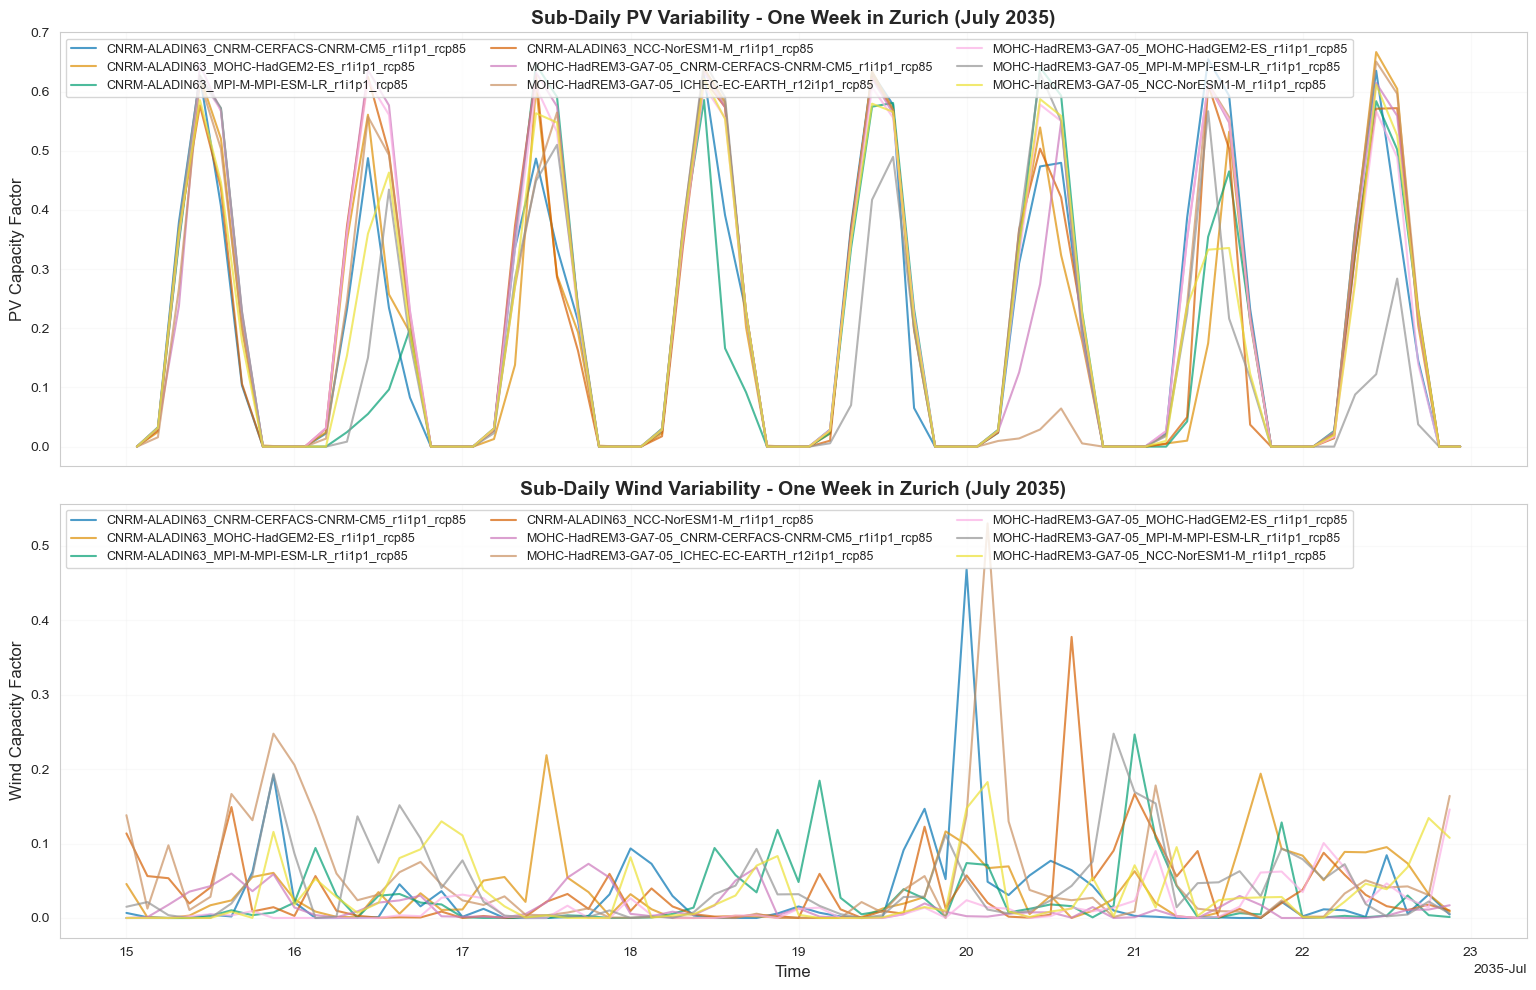

In [44]:
# Select a representative week in summer
week_start = "2035-07-15"
week_end = "2035-07-22"

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# PV - One week with all models
ax = axes[0]
for model in zurich_pv.model.values:
    zurich_pv.sel(model=model, time=slice(week_start, week_end)).pv.plot(
        label=model, ax=ax, alpha=0.7, linewidth=1.5
    )
ax.set_xlabel("")
ax.set_ylabel("PV Capacity Factor", fontsize=12)
ax.set_title("Sub-Daily PV Variability - One Week in Zurich (July 2035)", fontsize=14, fontweight='bold')
ax.legend(loc="upper left", ncol=3, fontsize=9)
ax.grid(True, alpha=0.3)

# Wind - One week with all models
ax = axes[1]
for model in zurich_wind.model.values:
    zurich_wind.sel(model=model, time=slice(week_start, week_end)).wind.plot(
        label=model, ax=ax, alpha=0.7, linewidth=1.5
    )
ax.set_xlabel("Time", fontsize=12)
ax.set_ylabel("Wind Capacity Factor", fontsize=12)
ax.set_title("Sub-Daily Wind Variability - One Week in Zurich (July 2035)", fontsize=14, fontweight='bold')
ax.legend(loc="upper left", ncol=3, fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

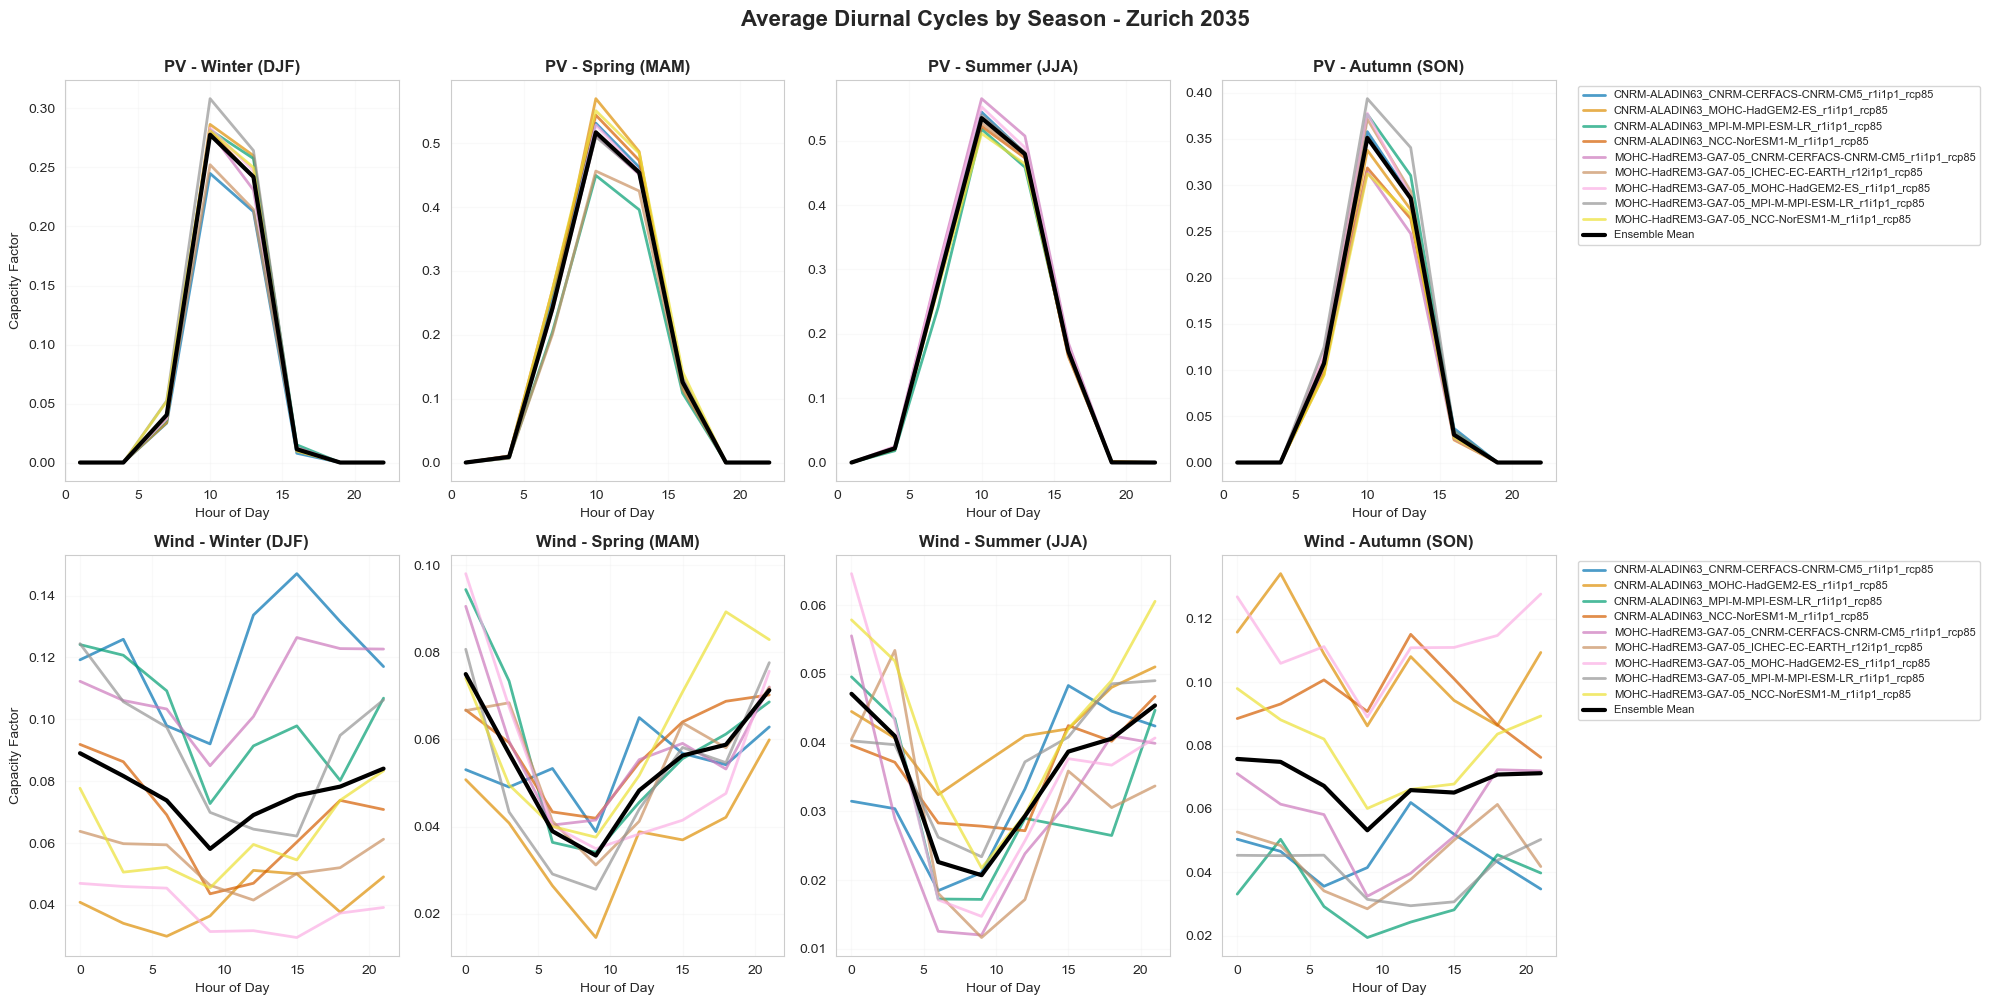

In [45]:
# Compare sub-daily patterns across seasons - average diurnal cycle
seasons = {
    'Winter (DJF)': [12, 1, 2],
    'Spring (MAM)': [3, 4, 5],
    'Summer (JJA)': [6, 7, 8],
    'Autumn (SON)': [9, 10, 11]
}

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

# PV diurnal cycles by season
for idx, (season_name, months) in enumerate(seasons.items()):
    ax = axes[0, idx]

    # Filter data for the season and year 2035
    seasonal_pv = zurich_pv.sel(
        time=(zurich_pv.time.dt.year == 2035) &
        (zurich_pv.time.dt.month.isin(months))
    )

    # Calculate mean diurnal cycle for each model
    for model in seasonal_pv.model.values:
        hourly_mean = seasonal_pv.sel(model=model).pv.groupby('time.hour').mean()
        ax.plot(hourly_mean.hour, hourly_mean, label=model, alpha=0.7, linewidth=2)

    # Add ensemble mean
    ensemble_mean = seasonal_pv.pv.groupby('time.hour').mean(dim=['time', 'model'])
    ax.plot(ensemble_mean.hour, ensemble_mean, 'k-', linewidth=3, label='Ensemble Mean')

    ax.set_title(f'PV - {season_name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Hour of Day', fontsize=10)
    ax.set_ylabel('Capacity Factor' if idx == 0 else '', fontsize=10)
    ax.grid(True, alpha=0.3)
    if idx == 3:
        ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), fontsize=8)

# Wind diurnal cycles by season
for idx, (season_name, months) in enumerate(seasons.items()):
    ax = axes[1, idx]

    # Filter data for the season and year 2035
    seasonal_wind = zurich_wind.sel(
        time=(zurich_wind.time.dt.year == 2035) &
        (zurich_wind.time.dt.month.isin(months))
    )

    # Calculate mean diurnal cycle for each model
    for model in seasonal_wind.model.values:
        hourly_mean = seasonal_wind.sel(model=model).wind.groupby('time.hour').mean()
        ax.plot(hourly_mean.hour, hourly_mean, label=model, alpha=0.7, linewidth=2)

    # Add ensemble mean
    ensemble_mean = seasonal_wind.wind.groupby('time.hour').mean(dim=['time', 'model'])
    ax.plot(ensemble_mean.hour, ensemble_mean, 'k-', linewidth=3, label='Ensemble Mean')

    ax.set_title(f'Wind - {season_name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Hour of Day', fontsize=10)
    ax.set_ylabel('Capacity Factor' if idx == 0 else '', fontsize=10)
    ax.grid(True, alpha=0.3)
    if idx == 3:
        ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), fontsize=8)

plt.suptitle('Average Diurnal Cycles by Season - Zurich 2035',
             fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

## 2. Value of Multi-Model Ensemble: Quantifying Uncertainty

Multiple climate models provide:
- **Uncertainty bounds** on future projections
- **Robust planning** based on ensemble statistics
- **Risk assessment** through model spread analysis

In [ ]:
# Daily variability and model spread - focus on one month
month_data_pv = zurich_pv.sel(
    time=(zurich_pv.time.dt.year == 2035) & (zurich_pv.time.dt.month == 7)
)
month_data_wind = zurich_wind.sel(
    time=(zurich_wind.time.dt.year == 2035) & (zurich_wind.time.dt.month == 7)
)

# Resample to daily mean for clearer visualization
daily_pv = month_data_pv.pv.resample(time='1D').mean()
daily_wind = month_data_wind.wind.resample(time='1D').mean()

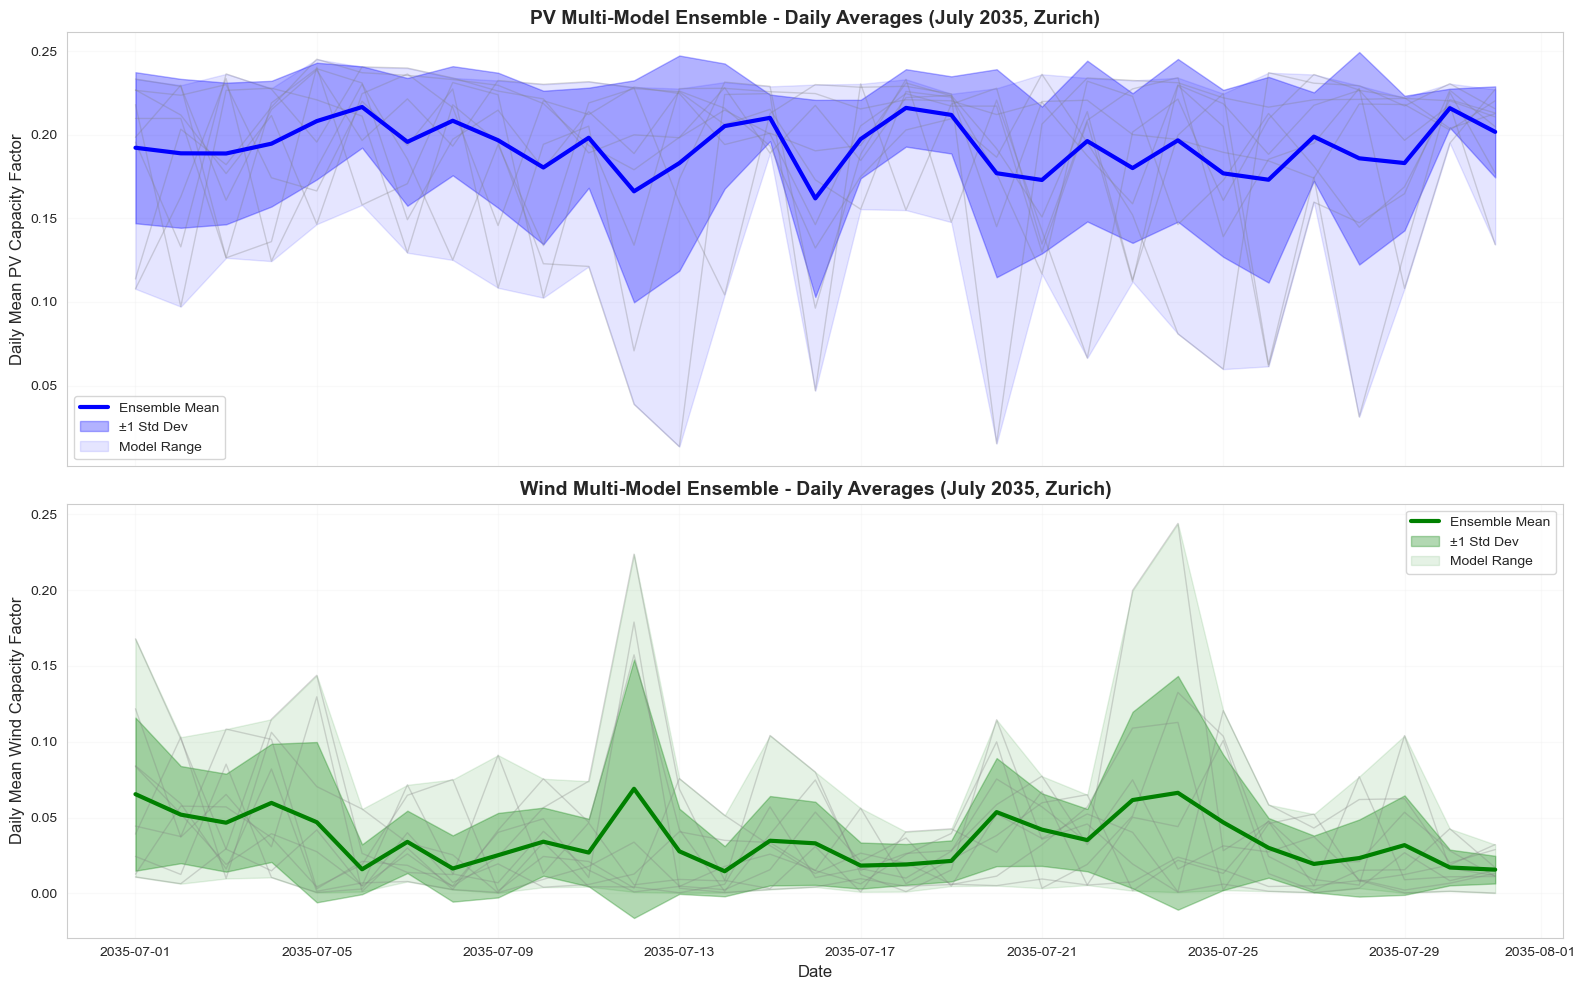

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# PV with uncertainty envelope
ax = axes[0]
ensemble_mean_pv = daily_pv.mean(dim='model')
ensemble_std_pv = daily_pv.std(dim='model')
ensemble_min_pv = daily_pv.min(dim='model')
ensemble_max_pv = daily_pv.max(dim='model')

# Plot individual models in light colors
for model in daily_pv.model.values:
    ax.plot(daily_pv.time, daily_pv.sel(model=model),
            alpha=0.3, linewidth=1, color='gray')

# Plot ensemble statistics
ax.plot(daily_pv.time, ensemble_mean_pv, 'b-', linewidth=3, label='Ensemble Mean')
ax.fill_between(daily_pv.time,
                ensemble_mean_pv - ensemble_std_pv,
                ensemble_mean_pv + ensemble_std_pv,
                alpha=0.3, color='blue', label='±1 Std Dev')
ax.fill_between(daily_pv.time, ensemble_min_pv, ensemble_max_pv,
                alpha=0.1, color='blue', label='Model Range')

ax.set_ylabel('Daily Mean PV Capacity Factor', fontsize=12)
ax.set_title('PV Multi-Model Ensemble - Daily Averages (July 2035, Zurich)',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Wind with uncertainty envelope
ax = axes[1]
ensemble_mean_wind = daily_wind.mean(dim='model')
ensemble_std_wind = daily_wind.std(dim='model')
ensemble_min_wind = daily_wind.min(dim='model')
ensemble_max_wind = daily_wind.max(dim='model')

# Plot individual models in light colors
for model in daily_wind.model.values:
    ax.plot(daily_wind.time, daily_wind.sel(model=model),
            alpha=0.3, linewidth=1, color='gray')

# Plot ensemble statistics
ax.plot(daily_wind.time, ensemble_mean_wind, 'g-', linewidth=3, label='Ensemble Mean')
ax.fill_between(daily_wind.time,
                ensemble_mean_wind - ensemble_std_wind,
                ensemble_mean_wind + ensemble_std_wind,
                alpha=0.3, color='green', label='±1 Std Dev')
ax.fill_between(daily_wind.time, ensemble_min_wind, ensemble_max_wind,
                alpha=0.1, color='green', label='Model Range')

ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Daily Mean Wind Capacity Factor', fontsize=12)
ax.set_title('Wind Multi-Model Ensemble - Daily Averages (July 2035, Zurich)',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Monthly Analysis: Seasonal Patterns Across Time Periods

In [66]:
# Define time periods
periods = {
    'Reference': REFERENCE_PERIOD,
    'Near Future': NEAR_FUTURE_PERIOD,
    'Mid Century': MID_CENTURY_PERIOD
}

# Prepare data for all periods
period_data_pv = {}
period_data_wind = {}

for period_name, years in periods.items():
    period_pv = zurich_pv.sel(time=slice(*years))
    period_wind = zurich_wind.sel(time=slice(*years))

    with ProgressBar():
        period_data_pv[period_name] = period_pv.pv.groupby('time.month').mean(dim='time').compute()
        period_data_wind[period_name] = period_wind.wind.groupby('time.month').mean(dim='time').compute()

[########################################] | 100% Completed | 5.24 sms
[########################################] | 100% Completed | 4.92 sms
[########################################] | 100% Completed | 5.31 sms
[########################################] | 100% Completed | 5.39 sms
[########################################] | 100% Completed | 3.54 sms
[########################################] | 100% Completed | 3.34 sms


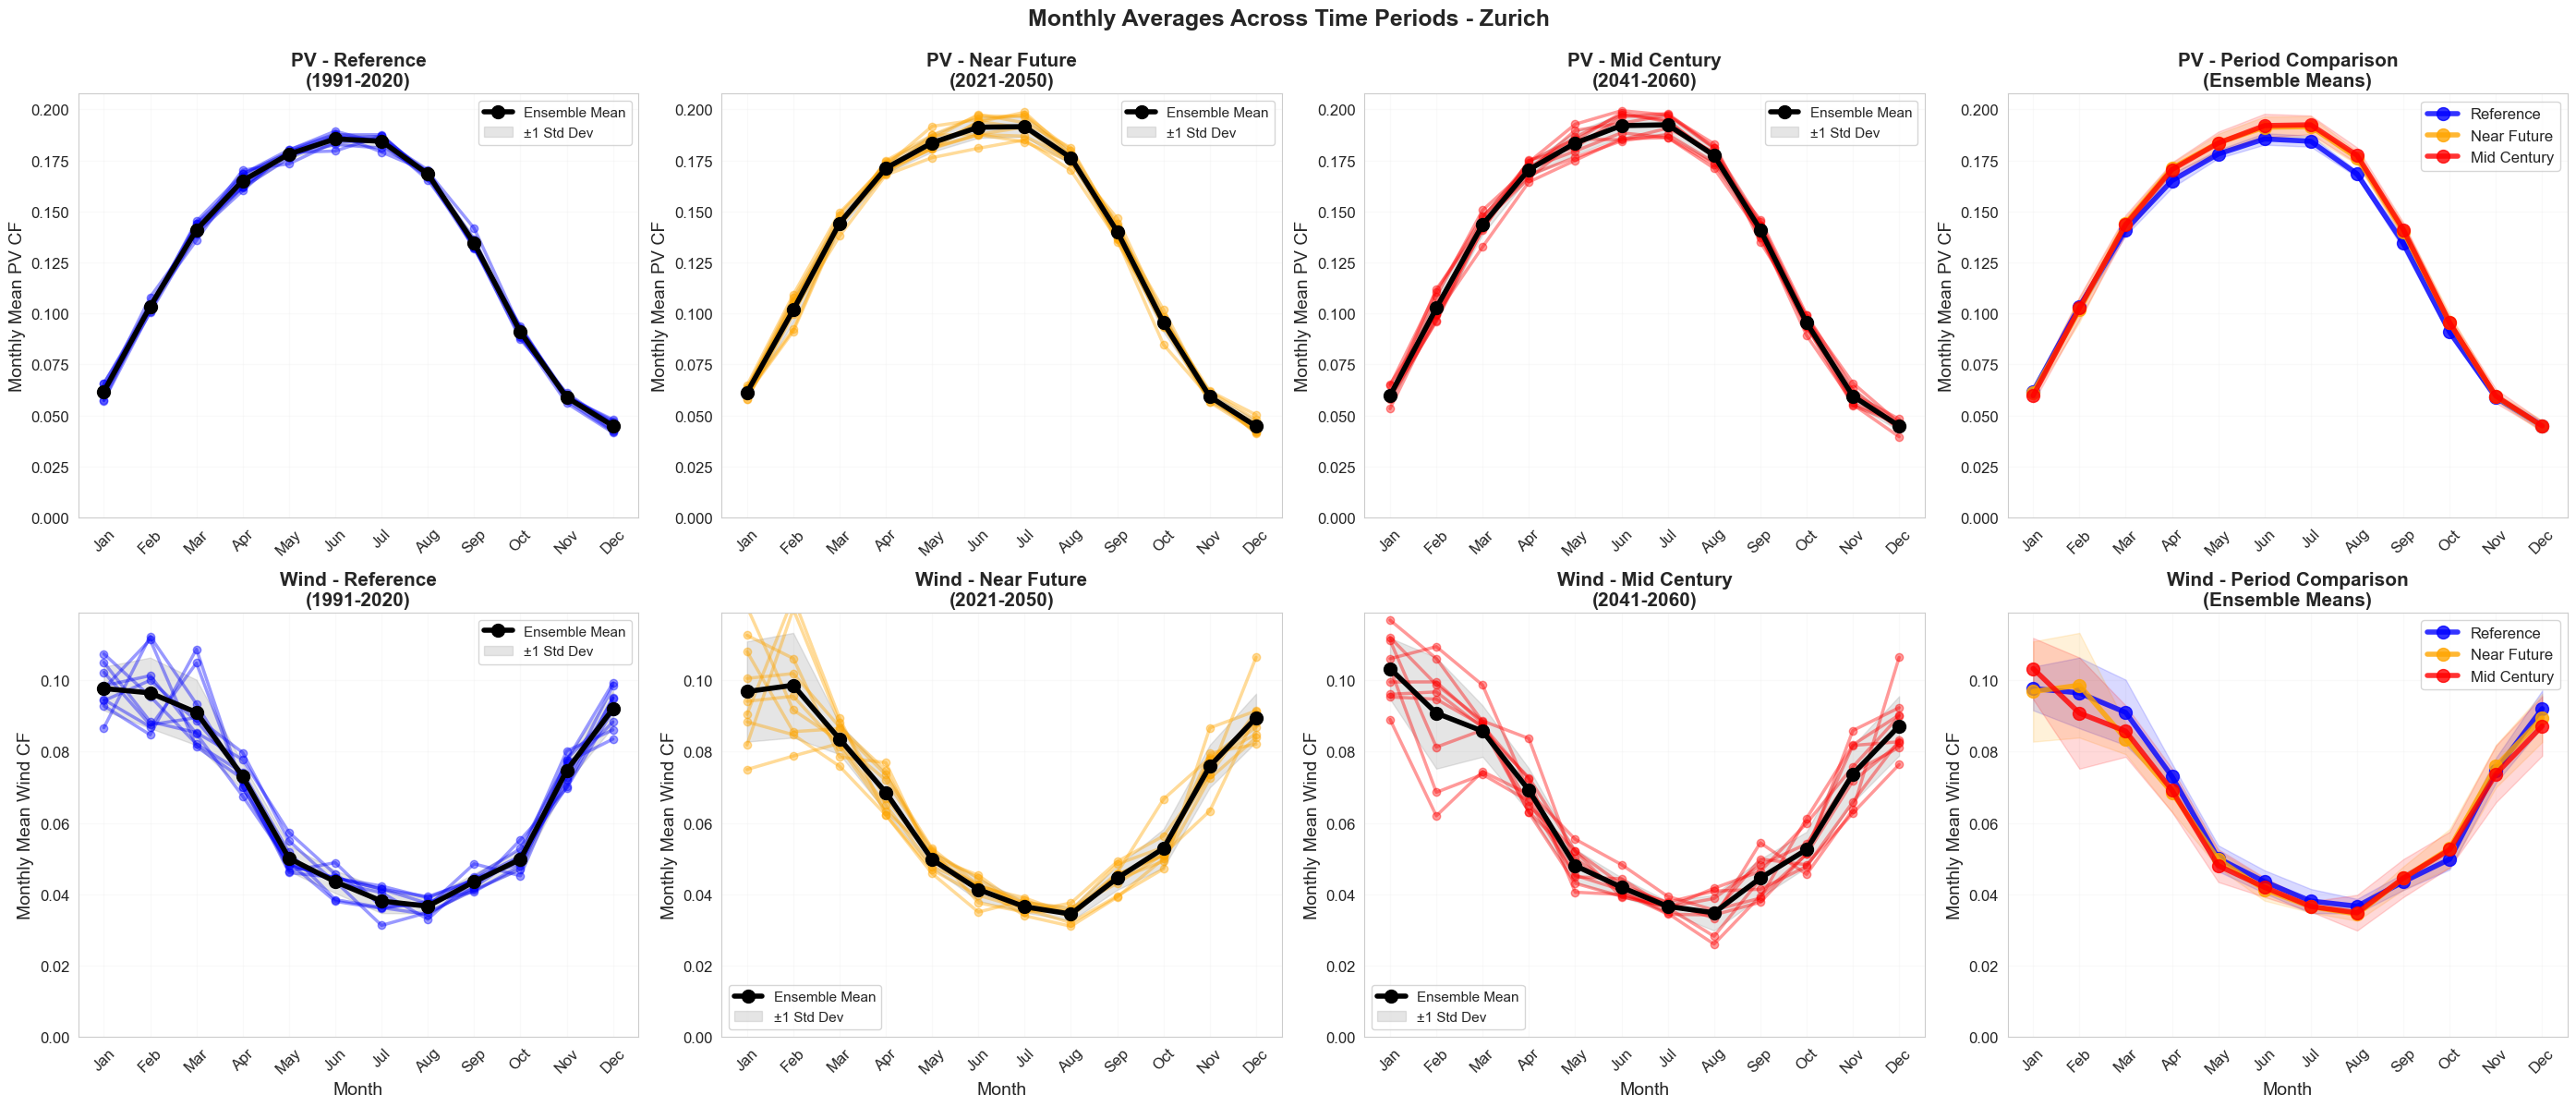

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(28, 12))

colors = {'Reference': 'blue', 'Near Future': 'orange', 'Mid Century': 'red'}
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Calculate common y-axis limits for each row
# PV y-axis range
pv_max_vals = []
for period_name, monthly_pv in period_data_pv.items():
    ensemble_mean = monthly_pv.mean(dim='model')
    ensemble_std = monthly_pv.std(dim='model')
    pv_max_vals.append((ensemble_mean + ensemble_std).max().values)
pv_y_max = max(pv_max_vals) * 1.05

# Wind y-axis range
wind_max_vals = []
for period_name, monthly_wind in period_data_wind.items():
    ensemble_mean = monthly_wind.mean(dim='model')
    ensemble_std = monthly_wind.std(dim='model')
    wind_max_vals.append((ensemble_mean + ensemble_std).max().values)
wind_y_max = max(wind_max_vals) * 1.05

# PV monthly - by period
for idx, (period_name, monthly_pv) in enumerate(period_data_pv.items()):
    ax = axes[0, idx]
    years = periods[period_name]
    # Plot individual models
    for model in monthly_pv.model.values:
        ax.plot(monthly_pv.month, monthly_pv.sel(model=model),
                'o-', alpha=0.4, linewidth=2.5, markersize=6, color=colors[period_name])

    # Plot ensemble mean
    ensemble_mean = monthly_pv.mean(dim='model')
    ensemble_std = monthly_pv.std(dim='model')
    ax.plot(monthly_pv.month, ensemble_mean,
            'o-', linewidth=4, markersize=10, label='Ensemble Mean',
            color='black', zorder=10)
    ax.fill_between(monthly_pv.month,
                    ensemble_mean - ensemble_std,
                    ensemble_mean + ensemble_std,
                    alpha=0.2, color='gray', label='±1 Std Dev')

    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_labels, rotation=45, fontsize=12)
    ax.set_ylabel('Monthly Mean PV CF', fontsize=14)
    ax.set_title(f'PV - {period_name}\n({years[0]}-{years[-1]})',
                 fontsize=15, fontweight='bold')
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, pv_y_max)
    ax.tick_params(axis='y', labelsize=12)

# PV comparison plot - all periods overlaid
ax = axes[0, 3]
for period_name, monthly_pv in period_data_pv.items():
    ensemble_mean = monthly_pv.mean(dim='model')
    ensemble_std = monthly_pv.std(dim='model')

    ax.plot(monthly_pv.month, ensemble_mean,
            'o-', linewidth=4, markersize=10, label=period_name,
            color=colors[period_name], alpha=0.8)
    ax.fill_between(monthly_pv.month,
                    ensemble_mean - ensemble_std,
                    ensemble_mean + ensemble_std,
                    alpha=0.15, color=colors[period_name])

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels, rotation=45, fontsize=12)
ax.set_ylabel('Monthly Mean PV CF', fontsize=14)
ax.set_title('PV - Period Comparison\n(Ensemble Means)',
             fontsize=15, fontweight='bold')
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)
ax.set_ylim(0, pv_y_max)
ax.tick_params(axis='y', labelsize=12)

# Wind monthly - by period
for idx, (period_name, monthly_wind) in enumerate(period_data_wind.items()):
    ax = axes[1, idx]
    years = periods[period_name]
    # Plot individual models
    for model in monthly_wind.model.values:
        ax.plot(monthly_wind.month, monthly_wind.sel(model=model),
                'o-', alpha=0.4, linewidth=2.5, markersize=6, color=colors[period_name])

    # Plot ensemble mean
    ensemble_mean = monthly_wind.mean(dim='model')
    ensemble_std = monthly_wind.std(dim='model')
    ax.plot(monthly_wind.month, ensemble_mean,
            'o-', linewidth=4, markersize=10, label='Ensemble Mean',
            color='black', zorder=10)
    ax.fill_between(monthly_wind.month,
                    ensemble_mean - ensemble_std,
                    ensemble_mean + ensemble_std,
                    alpha=0.2, color='gray', label='±1 Std Dev')

    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_labels, rotation=45, fontsize=12)
    ax.set_xlabel('Month', fontsize=14)
    ax.set_ylabel('Monthly Mean Wind CF', fontsize=14)
    ax.set_title(f'Wind - {period_name}\n({years[0]}-{years[-1]})',
                 fontsize=15, fontweight='bold')
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, wind_y_max)
    ax.tick_params(axis='y', labelsize=12)

# Wind comparison plot - all periods overlaid
ax = axes[1, 3]
for period_name, monthly_wind in period_data_wind.items():
    ensemble_mean = monthly_wind.mean(dim='model')
    ensemble_std = monthly_wind.std(dim='model')

    ax.plot(monthly_wind.month, ensemble_mean,
            'o-', linewidth=4, markersize=10, label=period_name,
            color=colors[period_name], alpha=0.8)
    ax.fill_between(monthly_wind.month,
                    ensemble_mean - ensemble_std,
                    ensemble_mean + ensemble_std,
                    alpha=0.15, color=colors[period_name])

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels, rotation=45, fontsize=12)
ax.set_xlabel('Month', fontsize=14)
ax.set_ylabel('Monthly Mean Wind CF', fontsize=14)
ax.set_title('Wind - Period Comparison\n(Ensemble Means)',
             fontsize=15, fontweight='bold')
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)
ax.set_ylim(0, wind_y_max)
ax.tick_params(axis='y', labelsize=12)

plt.suptitle('Monthly Averages Across Time Periods - Zurich',
             fontsize=18, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

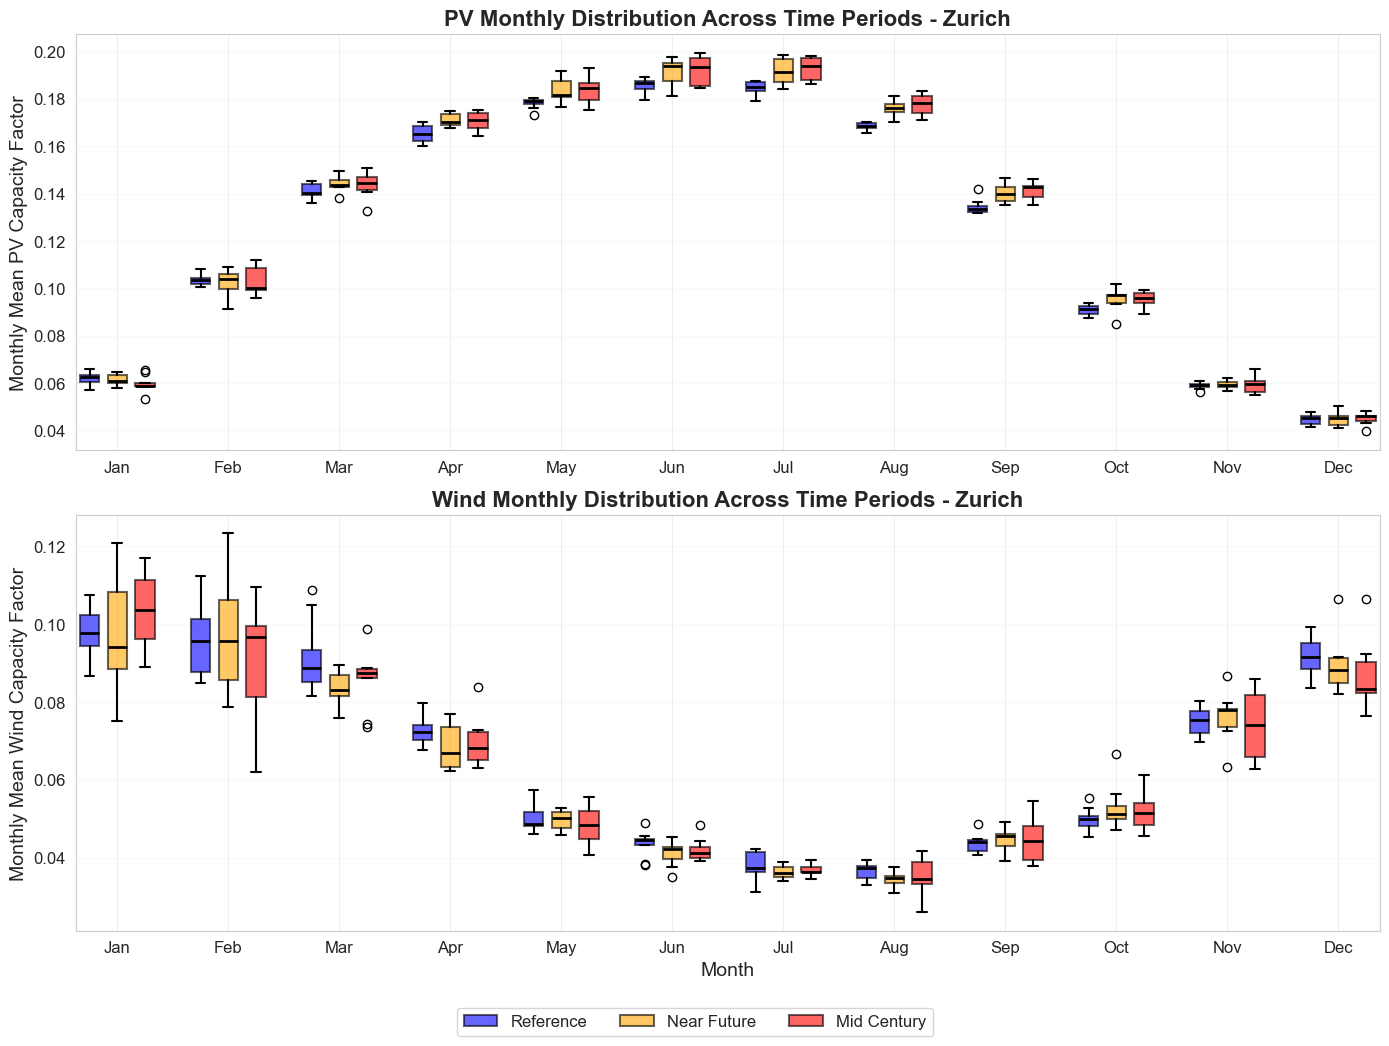

In [98]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
colors_periods = {'Reference': 'blue', 'Near Future': 'orange', 'Mid Century': 'red'}

# PV boxplots
ax = axes[0]
positions = []
box_data_pv = []

for month_idx, month in enumerate(range(1, 13)):
    for period_idx, (period_name, monthly_pv) in enumerate(period_data_pv.items()):
        # Get all model values for this month
        month_values = monthly_pv.sel(month=month).values
        box_data_pv.append(month_values)

        # Calculate position: month groups with spacing, periods side-by-side
        pos = month_idx * 4 + period_idx
        positions.append(pos)

bp = ax.boxplot(box_data_pv, positions=positions, widths=0.7,
                patch_artist=True, showfliers=True,
                boxprops=dict(linewidth=1.5),
                medianprops=dict(color='black', linewidth=2),
                whiskerprops=dict(linewidth=1.5),
                capprops=dict(linewidth=1.5))

# Color the boxes by period
for patch_idx, patch in enumerate(bp['boxes']):
    period_idx = patch_idx % 3
    period_name = list(period_data_pv.keys())[period_idx]
    patch.set_facecolor(colors_periods[period_name])
    patch.set_alpha(0.6)

ax.set_ylabel('Monthly Mean PV Capacity Factor', fontsize=14)
ax.set_title('PV Monthly Distribution Across Time Periods - Zurich', fontsize=16, fontweight='bold')
ax.set_xticks([i * 4 + 1 for i in range(12)])
ax.set_xticklabels(month_labels, fontsize=12)
ax.grid(True, alpha=0.3, axis='y')
ax.tick_params(axis='y', labelsize=12)

# Wind boxplots
ax = axes[1]
positions = []
box_data_wind = []

for month_idx, month in enumerate(range(1, 13)):
    for period_idx, (period_name, monthly_wind) in enumerate(period_data_wind.items()):
        # Get all model values for this month
        month_values = monthly_wind.sel(month=month).values
        box_data_wind.append(month_values)

        # Calculate position: month groups with spacing, periods side-by-side
        pos = month_idx * 4 + period_idx
        positions.append(pos)

bp = ax.boxplot(box_data_wind, positions=positions, widths=0.7,
                patch_artist=True, showfliers=True,
                boxprops=dict(linewidth=1.5),
                medianprops=dict(color='black', linewidth=2),
                whiskerprops=dict(linewidth=1.5),
                capprops=dict(linewidth=1.5))

# Color the boxes by period
for patch_idx, patch in enumerate(bp['boxes']):
    period_idx = patch_idx % 3
    period_name = list(period_data_wind.keys())[period_idx]
    patch.set_facecolor(colors_periods[period_name])
    patch.set_alpha(0.6)

ax.set_xlabel('Month', fontsize=14)
ax.set_ylabel('Monthly Mean Wind Capacity Factor', fontsize=14)
ax.set_title('Wind Monthly Distribution Across Time Periods - Zurich', fontsize=16, fontweight='bold')
ax.set_xticks([i * 4 + 1 for i in range(12)])
ax.set_xticklabels(month_labels, fontsize=12)
ax.grid(True, alpha=0.3, axis='y')
ax.tick_params(axis='y', labelsize=12)

# Common legend below second subplot
legend_elements = [plt.Rectangle((0,0),1,1, facecolor=colors_periods[name], alpha=0.6, edgecolor='black', linewidth=1.5, label=name)
                   for name in period_data_pv.keys()]
fig.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.5, -0.05),
           ncol=3, fontsize=12, frameon=True)

plt.tight_layout()
plt.savefig("figs/zurich_pv_wind_monthly_boxplots.png", bbox_inches='tight', dpi=300)
plt.show()

## 4. Seasonal Analysis: Evolution Across Time Periods

In [ ]:
# Define seasons
seasons_dict = {
    'Winter (DJF)': [12, 1, 2],
    'Spring (MAM)': [3, 4, 5],
    'Summer (JJA)': [6, 7, 8],
    'Autumn (SON)': [9, 10, 11]
}

# Prepare seasonal data for all periods
period_seasonal_pv = {}
period_seasonal_wind = {}

for period_name, years in periods.items():
    period_pv = zurich_pv.sel(time=slice(*years))
    period_wind = zurich_wind.sel(time=slice(*years))

    seasonal_means_pv = []
    seasonal_means_wind = []

    for season_name, months in seasons_dict.items():
        season_pv = period_pv.sel(time=period_pv.time.dt.month.isin(months)).pv.mean(dim='time')
        season_wind = period_wind.sel(time=period_wind.time.dt.month.isin(months)).wind.mean(dim='time')
        seasonal_means_pv.append(season_pv)
        seasonal_means_wind.append(season_wind)

    period_seasonal_pv[period_name] = seasonal_means_pv
    period_seasonal_wind[period_name] = seasonal_means_wind


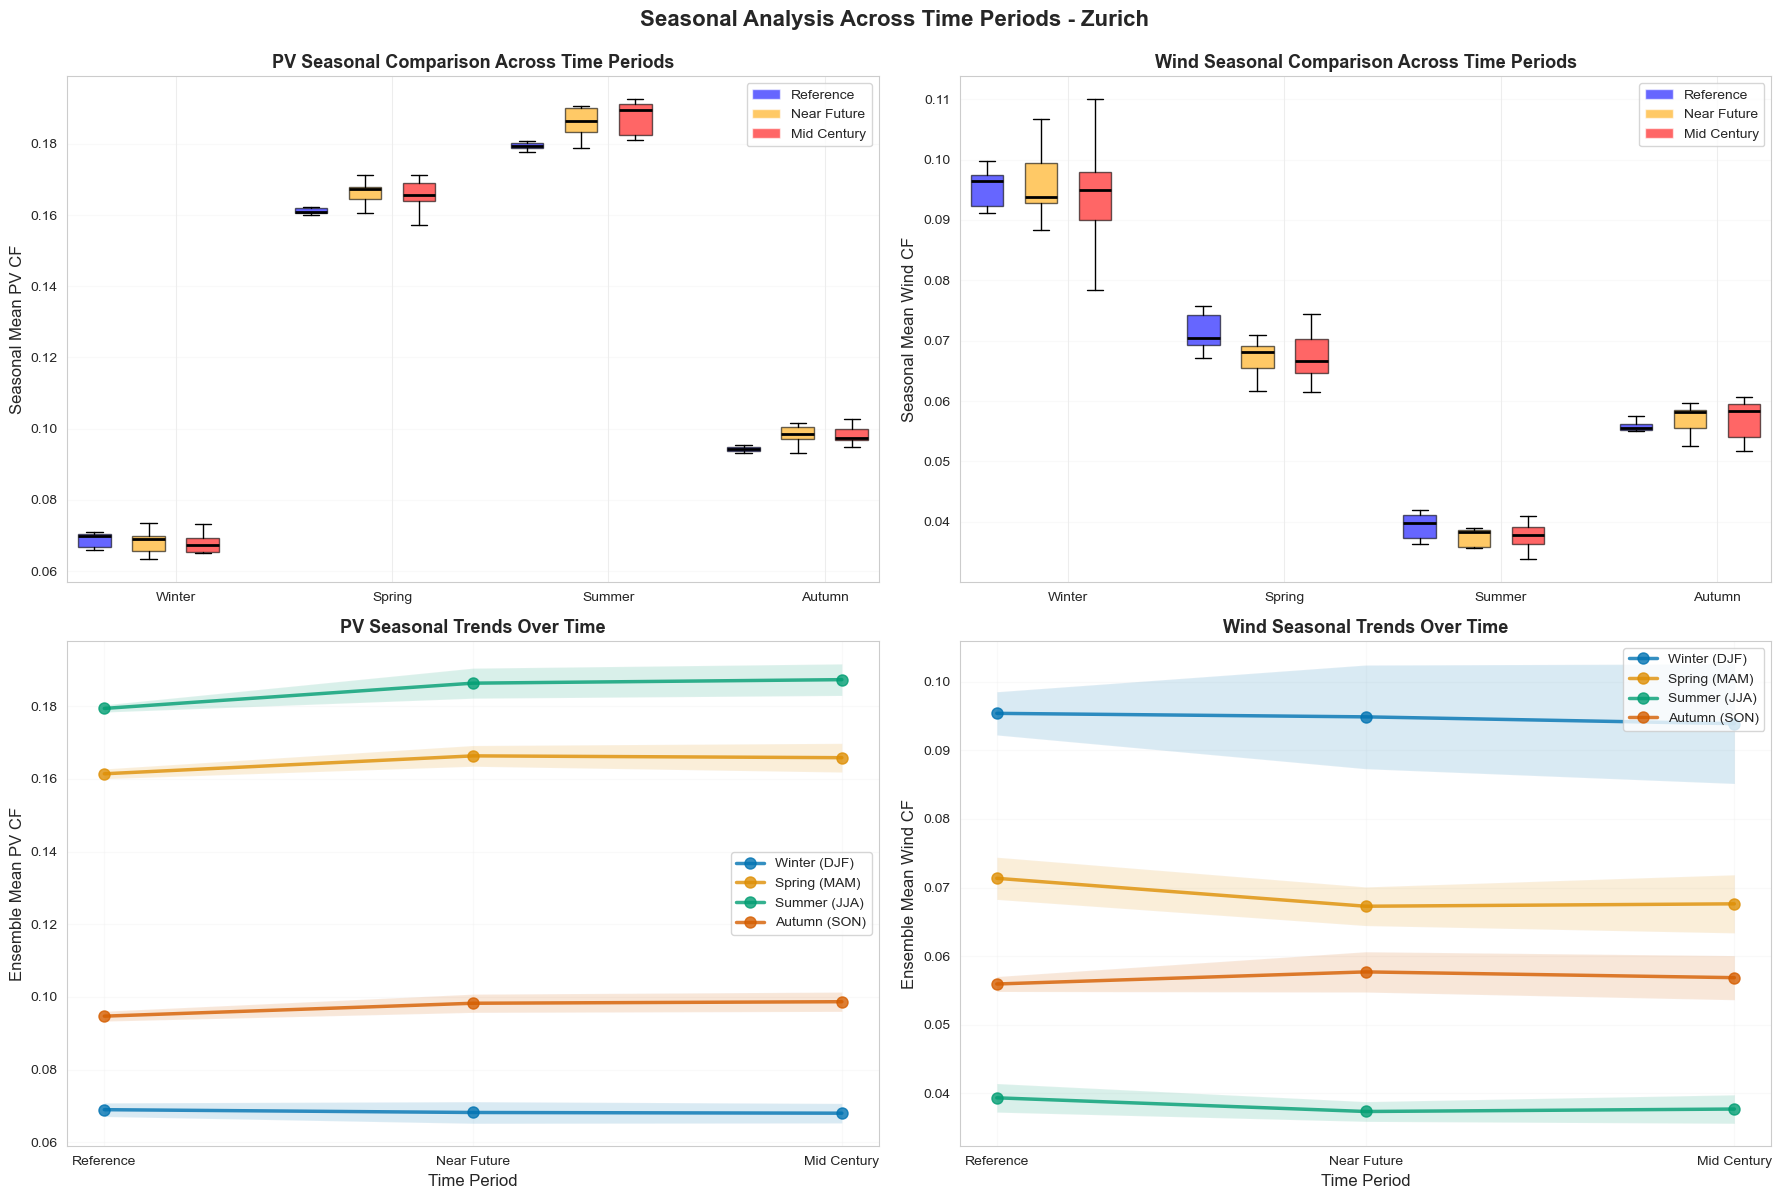

In [57]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
season_labels = list(seasons_dict.keys())
colors_periods = {'Reference': 'blue', 'Near Future': 'orange', 'Mid Century': 'red'}

# PV - Seasonal boxplots by period
ax = axes[0, 0]
positions = []
all_pv_data = []
for season_idx in range(4):
    for period_idx, (period_name, seasonal_data) in enumerate(period_seasonal_pv.items()):
        pos = season_idx * 4 + period_idx + 1
        positions.append(pos)
        season_data = seasonal_data[season_idx].values
        all_pv_data.append(season_data)

        bp = ax.boxplot([season_data], positions=[pos], widths=0.6,
                        patch_artist=True, showfliers=False,
                        boxprops=dict(facecolor=colors_periods[period_name], alpha=0.6),
                        medianprops=dict(color='black', linewidth=2))

ax.set_ylabel('Seasonal Mean PV CF', fontsize=12)
ax.set_title('PV Seasonal Comparison Across Time Periods', fontsize=13, fontweight='bold')
ax.set_xticks([2.5, 6.5, 10.5, 14.5])
ax.set_xticklabels([s.split('(')[0].strip() for s in season_labels])
ax.grid(True, alpha=0.3, axis='y')

# Create custom legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=colors_periods[p], alpha=0.6, label=p)
                   for p in periods.keys()]
ax.legend(handles=legend_elements, fontsize=10, loc='upper right')

# Wind - Seasonal boxplots by period
ax = axes[0, 1]
for season_idx in range(4):
    for period_idx, (period_name, seasonal_data) in enumerate(period_seasonal_wind.items()):
        pos = season_idx * 4 + period_idx + 1
        season_data = seasonal_data[season_idx].values

        bp = ax.boxplot([season_data], positions=[pos], widths=0.6,
                        patch_artist=True, showfliers=False,
                        boxprops=dict(facecolor=colors_periods[period_name], alpha=0.6),
                        medianprops=dict(color='black', linewidth=2))

ax.set_ylabel('Seasonal Mean Wind CF', fontsize=12)
ax.set_title('Wind Seasonal Comparison Across Time Periods', fontsize=13, fontweight='bold')
ax.set_xticks([2.5, 6.5, 10.5, 14.5])
ax.set_xticklabels([s.split('(')[0].strip() for s in season_labels])
ax.grid(True, alpha=0.3, axis='y')
ax.legend(handles=legend_elements, fontsize=10, loc='upper right')

# PV - Seasonal evolution line plot
ax = axes[1, 0]
for season_idx, season_name in enumerate(season_labels):
    period_names = list(periods.keys())
    ensemble_means = []
    ensemble_stds = []

    for period_name in period_names:
        data = period_seasonal_pv[period_name][season_idx]
        ensemble_means.append(data.mean().values)
        ensemble_stds.append(data.std().values)

    x_pos = np.arange(len(period_names))
    ax.plot(x_pos, ensemble_means, 'o-', linewidth=2.5, markersize=8,
            label=season_name, alpha=0.8)
    ax.fill_between(x_pos,
                    np.array(ensemble_means) - np.array(ensemble_stds),
                    np.array(ensemble_means) + np.array(ensemble_stds),
                    alpha=0.15)

ax.set_xticks(range(len(period_names)))
ax.set_xticklabels(period_names)
ax.set_ylabel('Ensemble Mean PV CF', fontsize=12)
ax.set_xlabel('Time Period', fontsize=12)
ax.set_title('PV Seasonal Trends Over Time', fontsize=13, fontweight='bold')
ax.legend(fontsize=10, loc='best')
ax.grid(True, alpha=0.3)

# Wind - Seasonal evolution line plot
ax = axes[1, 1]
for season_idx, season_name in enumerate(season_labels):
    period_names = list(periods.keys())
    ensemble_means = []
    ensemble_stds = []

    for period_name in period_names:
        data = period_seasonal_wind[period_name][season_idx]
        ensemble_means.append(data.mean().values)
        ensemble_stds.append(data.std().values)

    x_pos = np.arange(len(period_names))
    ax.plot(x_pos, ensemble_means, 'o-', linewidth=2.5, markersize=8,
            label=season_name, alpha=0.8)
    ax.fill_between(x_pos,
                    np.array(ensemble_means) - np.array(ensemble_stds),
                    np.array(ensemble_means) + np.array(ensemble_stds),
                    alpha=0.15)

ax.set_xticks(range(len(period_names)))
ax.set_xticklabels(period_names)
ax.set_ylabel('Ensemble Mean Wind CF', fontsize=12)
ax.set_xlabel('Time Period', fontsize=12)
ax.set_title('Wind Seasonal Trends Over Time', fontsize=13, fontweight='bold')
ax.legend(fontsize=10, loc='best')
ax.grid(True, alpha=0.3)

plt.suptitle('Seasonal Analysis Across Time Periods - Zurich',
             fontsize=16, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

## 5. Yearly Analysis: Long-Term Trends and Model Spread

In [68]:
with ProgressBar():
    yearly_pv = zurich_pv.pv.resample(time='YE').mean().compute()
    yearly_wind = zurich_wind.wind.resample(time='YE').mean().compute()

[########################################] | 100% Completed | 18.94 s
[########################################] | 100% Completed | 18.60 s


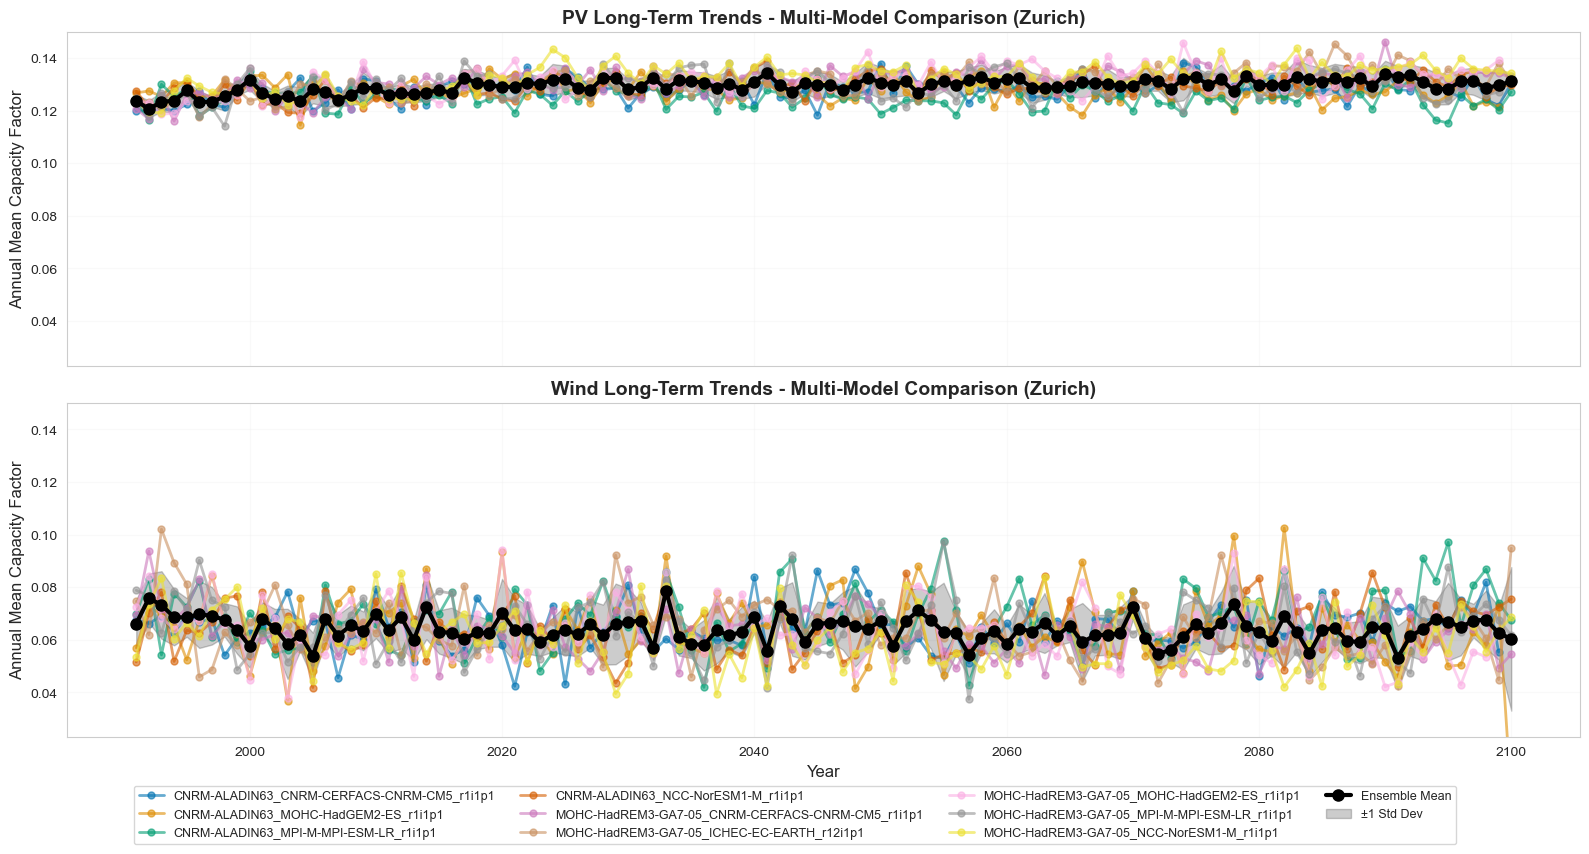

In [77]:
# Yearly aggregation - multi-year time series
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

# Calculate common y-axis limits
pv_min = (yearly_pv.mean(dim='model') - yearly_pv.std(dim='model')).min().values
pv_max = (yearly_pv.mean(dim='model') + yearly_pv.std(dim='model')).max().values
wind_min = (yearly_wind.mean(dim='model') - yearly_wind.std(dim='model')).min().values
wind_max = (yearly_wind.mean(dim='model') + yearly_wind.std(dim='model')).max().values
y_min = min(pv_min, wind_min) - 0.01
y_max = max(pv_max, wind_max) + 0.01

# PV yearly trends
ax = axes[0]
for model in yearly_pv.model.values:
    ax.plot(yearly_pv.time.dt.year, yearly_pv.sel(model=model),
            'o-', label=model.split(f"_{climate_scenario}")[0], alpha=0.6, linewidth=2, markersize=5)

ensemble_mean = yearly_pv.mean(dim='model')
ensemble_std = yearly_pv.std(dim='model')
ax.plot(yearly_pv.time.dt.year, ensemble_mean,
        'ko-', linewidth=3, markersize=8, label='Ensemble Mean', zorder=10)
ax.fill_between(yearly_pv.time.dt.year,
                ensemble_mean - ensemble_std,
                ensemble_mean + ensemble_std,
                alpha=0.2, color='black', label='±1 Std Dev')

ax.set_ylabel('Annual Mean Capacity Factor', fontsize=12)
ax.set_title('PV Long-Term Trends - Multi-Model Comparison (Zurich)',
             fontsize=14, fontweight='bold')
ax.set_ylim(y_min, y_max)
ax.grid(True, alpha=0.3)

# Wind yearly trends
ax = axes[1]
for model in yearly_wind.model.values:
    ax.plot(yearly_wind.time.dt.year, yearly_wind.sel(model=model),
            'o-', label=model.split(f"_{climate_scenario}")[0], alpha=0.6, linewidth=2, markersize=5)

ensemble_mean = yearly_wind.mean(dim='model')
ensemble_std = yearly_wind.std(dim='model')
ax.plot(yearly_wind.time.dt.year, ensemble_mean,
        'ko-', linewidth=3, markersize=8, label='Ensemble Mean', zorder=10)
ax.fill_between(yearly_wind.time.dt.year,
                ensemble_mean - ensemble_std,
                ensemble_mean + ensemble_std,
                alpha=0.2, color='black', label='±1 Std Dev')

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Annual Mean Capacity Factor', fontsize=12)
ax.set_title('Wind Long-Term Trends - Multi-Model Comparison (Zurich)',
             fontsize=14, fontweight='bold')
ax.set_ylim(y_min, y_max)
ax.grid(True, alpha=0.3)

# Get handles and labels from the last subplot
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.07),
           ncol=4, fontsize=9, frameon=True)

plt.tight_layout()
plt.show()

## 8. Summary Statistics: Quantifying Multi-Model Value

In [ ]:
# Create comprehensive summary table
print("="*80)
print("MULTI-MODEL ENSEMBLE VALUE - SUMMARY STATISTICS (Zurich, 2035)")
print("="*80)
print()

year_2035_pv_full = zurich_pv.sel(time=zurich_pv.time.dt.year == 2035).pv
year_2035_wind_full = zurich_wind.sel(time=zurich_wind.time.dt.year == 2035).wind

# PV Statistics
print("PV CAPACITY FACTOR STATISTICS:")
print("-"*80)
pv_stats = pd.DataFrame({
    'Model': list(year_2035_pv_full.model.values) + ['ENSEMBLE MEAN', 'ENSEMBLE STD'],
    'Annual Mean': list(year_2035_pv_full.mean(dim='time').values) +
                   [year_2035_pv_full.mean(dim=['time', 'model']).values,
                    year_2035_pv_full.mean(dim='time').std(dim='model').values],
    'Annual Std': list(year_2035_pv_full.std(dim='time').values) +
                  [year_2035_pv_full.std(dim='time').mean(dim='model').values, np.nan],
    'Max Hourly': list(year_2035_pv_full.max(dim='time').values) +
                  [year_2035_pv_full.max(dim='time').mean(dim='model').values,
                   year_2035_pv_full.max(dim='time').std(dim='model').values],
    'Min Hourly': list(year_2035_pv_full.min(dim='time').values) +
                  [year_2035_pv_full.min(dim='time').mean(dim='model').values,
                   year_2035_pv_full.min(dim='time').std(dim='model').values]
})
print(pv_stats.to_string(index=False))
print()

# Wind Statistics
print("WIND CAPACITY FACTOR STATISTICS:")
print("-"*80)
wind_stats = pd.DataFrame({
    'Model': list(year_2035_wind_full.model.values) + ['ENSEMBLE MEAN', 'ENSEMBLE STD'],
    'Annual Mean': list(year_2035_wind_full.mean(dim='time').values) +
                   [year_2035_wind_full.mean(dim=['time', 'model']).values,
                    year_2035_wind_full.mean(dim='time').std(dim='model').values],
    'Annual Std': list(year_2035_wind_full.std(dim='time').values) +
                  [year_2035_wind_full.std(dim='time').mean(dim='model').values, np.nan],
    'Max Hourly': list(year_2035_wind_full.max(dim='time').values) +
                  [year_2035_wind_full.max(dim='time').mean(dim='model').values,
                   year_2035_wind_full.max(dim='time').std(dim='model').values],
    'Min Hourly': list(year_2035_wind_full.min(dim='time').values) +
                  [year_2035_wind_full.min(dim='time').mean(dim='model').values,
                   year_2035_wind_full.min(dim='time').std(dim='model').values]
})
print(wind_stats.to_string(index=False))
print()

# Model spread analysis
print("MODEL SPREAD ANALYSIS:")
print("-"*80)
print(f"Number of climate models: {len(year_2035_pv_full.model)}")
print()
print(f"PV Annual Mean - Model Range: {year_2035_pv_full.mean(dim='time').min().values:.4f} to {year_2035_pv_full.mean(dim='time').max().values:.4f}")
print(f"PV Annual Mean - Coefficient of Variation: {(year_2035_pv_full.mean(dim='time').std(dim='model') / year_2035_pv_full.mean(dim=['time','model'])).values:.2%}")
print()
print(f"Wind Annual Mean - Model Range: {year_2035_wind_full.mean(dim='time').min().values:.4f} to {year_2035_wind_full.mean(dim='time').max().values:.4f}")
print(f"Wind Annual Mean - Coefficient of Variation: {(year_2035_wind_full.mean(dim='time').std(dim='model') / year_2035_wind_full.mean(dim=['time','model'])).values:.2%}")
print()

# Temporal resolution impact
print("TEMPORAL RESOLUTION IMPACT:")
print("-"*80)
hourly_max_pv = year_2035_pv_full.mean(dim='model').max().values
daily_max_pv = year_2035_pv_full.resample(time='1D').mean().mean(dim='model').max().values
monthly_max_pv = year_2035_pv_full.resample(time='1ME').mean().mean(dim='model').max().values

hourly_max_wind = year_2035_wind_full.mean(dim='model').max().values
daily_max_wind = year_2035_wind_full.resample(time='1D').mean().mean(dim='model').max().values
monthly_max_wind = year_2035_wind_full.resample(time='1ME').mean().mean(dim='model').max().values
print(f"PV Maximum Capacity Factor:")
print(f"  Hourly:  {hourly_max_pv:.4f}")
print(f"  Daily:   {daily_max_pv:.4f} (missed: {(hourly_max_pv-daily_max_pv)/hourly_max_pv:.1%})")
print(f"  Monthly: {monthly_max_pv:.4f} (missed: {(hourly_max_pv-monthly_max_pv)/hourly_max_pv:.1%})")
print()
print(f"Wind Maximum Capacity Factor:")
print(f"  Hourly:  {hourly_max_wind:.4f}")
print(f"  Daily:   {daily_max_wind:.4f} (missed: {(hourly_max_wind-daily_max_wind)/hourly_max_wind:.1%})")
print(f"  Monthly: {monthly_max_wind:.4f} (missed: {(hourly_max_wind-monthly_max_wind)/hourly_max_wind:.1%})")
print()
print("="*80)

MULTI-MODEL ENSEMBLE VALUE - SUMMARY STATISTICS (Zurich, 2035)

PV CAPACITY FACTOR STATISTICS:
--------------------------------------------------------------------------------
                                                 Model           Annual Mean        Annual Std          Max Hourly Min Hourly
      CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85              0.131313          0.201263            0.735753        0.0
            CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1_rcp85              0.132498          0.201661            0.744202        0.0
           CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1_rcp85              0.125195          0.190932            0.708033        0.0
              CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1_rcp85              0.130856          0.199892            0.757693        0.0
MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85              0.131242          0.201636            0.753888        0.0
      MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1_rcp85              

## Key Takeaways

### Value of Sub-Daily Resolution:
1. **Captures diurnal patterns** - Critical for understanding solar ramps, wind diurnal cycles
2. **Identifies peak events** - Daily/monthly averages miss 10-30% of extreme values
3. **Enables accurate system planning** - Storage sizing, grid flexibility requirements depend on hourly variability
4. **Reveals complementarity** - PV-wind correlation varies by time of day

### Value of Multi-Model Ensemble:
1. **Quantifies uncertainty** - Model spread provides confidence intervals for planning
2. **Robust decision-making** - Ensemble mean more reliable than any single model
3. **Risk assessment** - Full model range captures best/worst case scenarios
4. **Validates projections** - Agreement across models increases confidence

### Multi-Scale Insights:
- **Hourly**: Operational planning, storage dispatch, grid balancing
- **Daily**: Short-term forecasting, demand matching
- **Monthly**: Seasonal storage requirements, capacity planning
- **Seasonal**: Long-term energy balance, resource adequacy
- **Yearly**: Investment decisions, policy planning, climate trends